In [1]:
import torch.nn as nn
from pathlib import Path
import numpy as np

import import_ipynb
import os
curdir = os.getcwd()
src_path = Path('../src/')
os.chdir(src_path)
from ML_Base import XANESVisualizer, XANESDataLoader, XANESPipeline
from Wrappers import TorchWrapper
os.chdir(curdir)

In [2]:
class XanesNN_JanisLike(nn.Module):
    def __init__(self,in_dim):
        super().__init__()
        self.in_dim=in_dim
        self.model = nn.Sequential(nn.Linear(self.in_dim, 387), # Входной слой (129) -> Скрытый 1 
                                   nn.Tanh(), # nn.Tanh(), у Яниса Tanh 
                                   nn.Linear(387, 387), # Скрытый 1 -> Скрытый 2 
                                   nn.Tanh(), # 
                                   nn.Linear(387, 1)
                                  )
    
    def forward(self, x):
        return self.model(x)

In [3]:
# Пути к сценарию 1A
paths_JanisLike = {
                    'train_x': Path('../processed_data/DataSets/JanisLike_Train_X.npz'),
                    'train_y': Path('../processed_data/DataSets/JanisLike_Train_y.npz'),
                    'test_x':  Path('../processed_data/DataSets/JanisLike_Test_X.npz'),
                    'test_y':  Path('../processed_data/DataSets/JanisLike_Test_y.npz'),
                  }

# Пути к сценарию 1B
paths_NotJanisLike = {
                    'train_x': Path('../processed_data/DataSets/NotJanisLike_Train_X.npz'),
                    'train_y': Path('../processed_data/DataSets/NotJanisLike_Train_y.npz'),
                    'test_x':  Path('../processed_data/DataSets/NotJanisLike_Test_X.npz'),
                    'test_y':  Path('../processed_data/DataSets/NotJanisLike_Test_y.npz'),
                  }

# Пути к сценарию 2A
paths_No_Strict = {
                    'train_x': Path('../processed_data/DataSets/No_Strict2A_Train_X.npz'),
                    'train_y': Path('../processed_data/DataSets/No_Strict2A_Train_y.npz'),
                    'test_x':  Path('../processed_data/DataSets/No_Strict2A_Test_X.npz'),
                    'test_y':  Path('../processed_data/DataSets/No_Strict2A_Test_y.npz'),
                  }


# Пути к сценарию 2B
paths_Lauvian = {
                    'train_x': Path('../processed_data/DataSets/Lauvian2B_Train_X.npz'),
                    'train_y': Path('../processed_data/DataSets/Lauvian2B_Train_y.npz'),
                    'test_x':  Path('../processed_data/DataSets/Lauvian2B_Test_X.npz'),
                    'test_y':  Path('../processed_data/DataSets/Lauvian2B_Test_y.npz'),
                }

In [4]:
# Используем стандартизацию данных или нет.
STAND = True
IN_DIM=141 # Размер входного спектра.
E_GRID = np.arange(-10,60.1,0.5) # Сетка энергий для спектра

In [5]:
params = {'epochs':480, 
          'batch_size':512, 
          'lr':1e-3, 
          'weight_decay': 0, #0, #1e-3, 
          'loss_params':{'alpha':1.0, 'beta':1., 'gamma':0.}, # MSE (0,1,0)-MAE, (0,0,1)-Mape 
          'T_0':80, 
          'T_mult':2, 
          'eta_min':1e-6, 
          'patience':160, 
          'min_delta':0,
         }

### Cценарий1A (JanisLike) (возможна утечка данных)


🚀 Моделирование CN1...


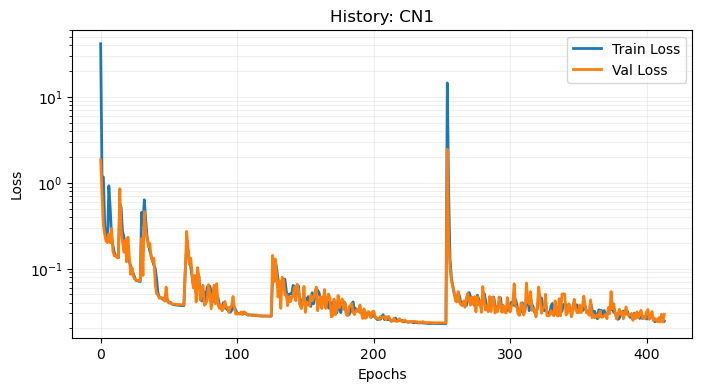

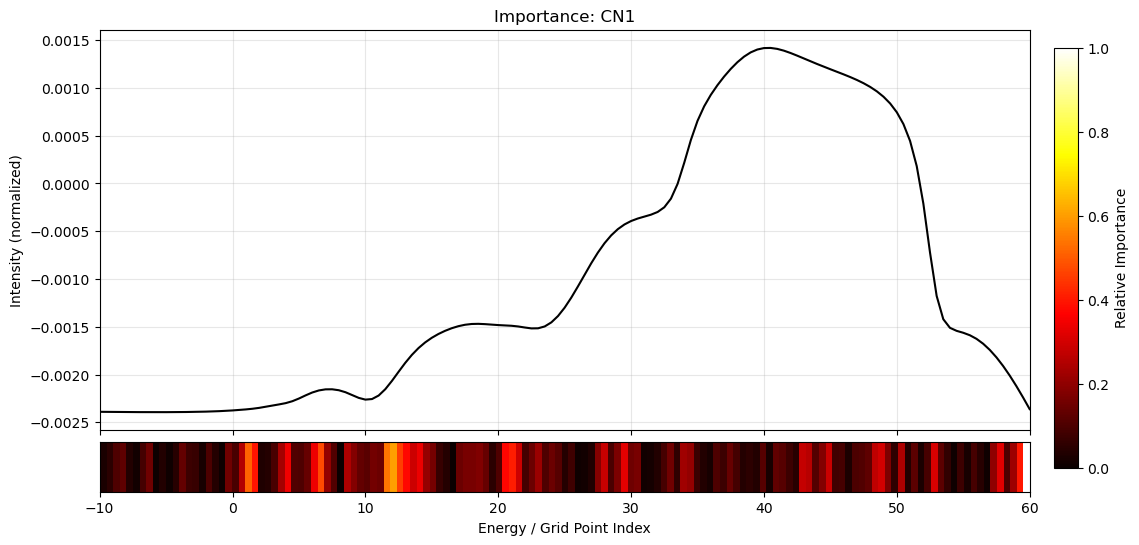

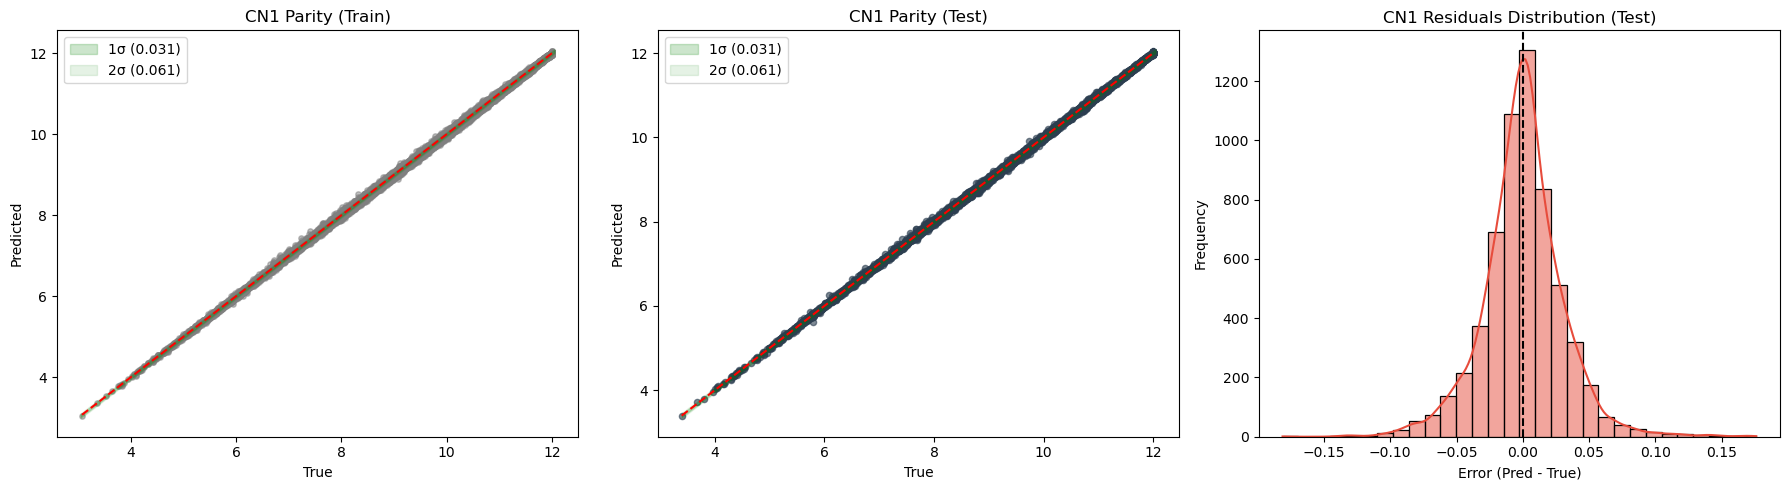


🚀 Моделирование CN2...


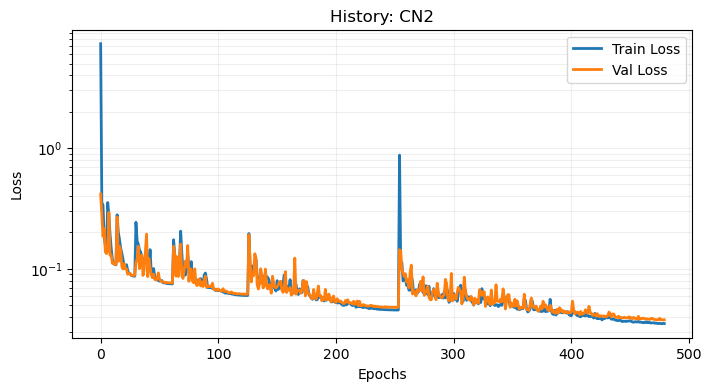

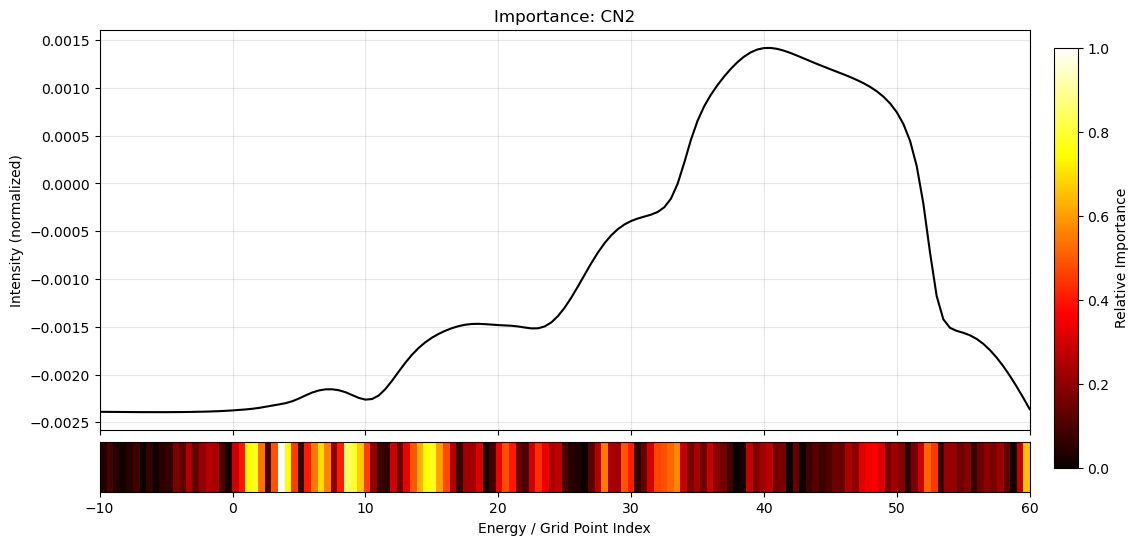

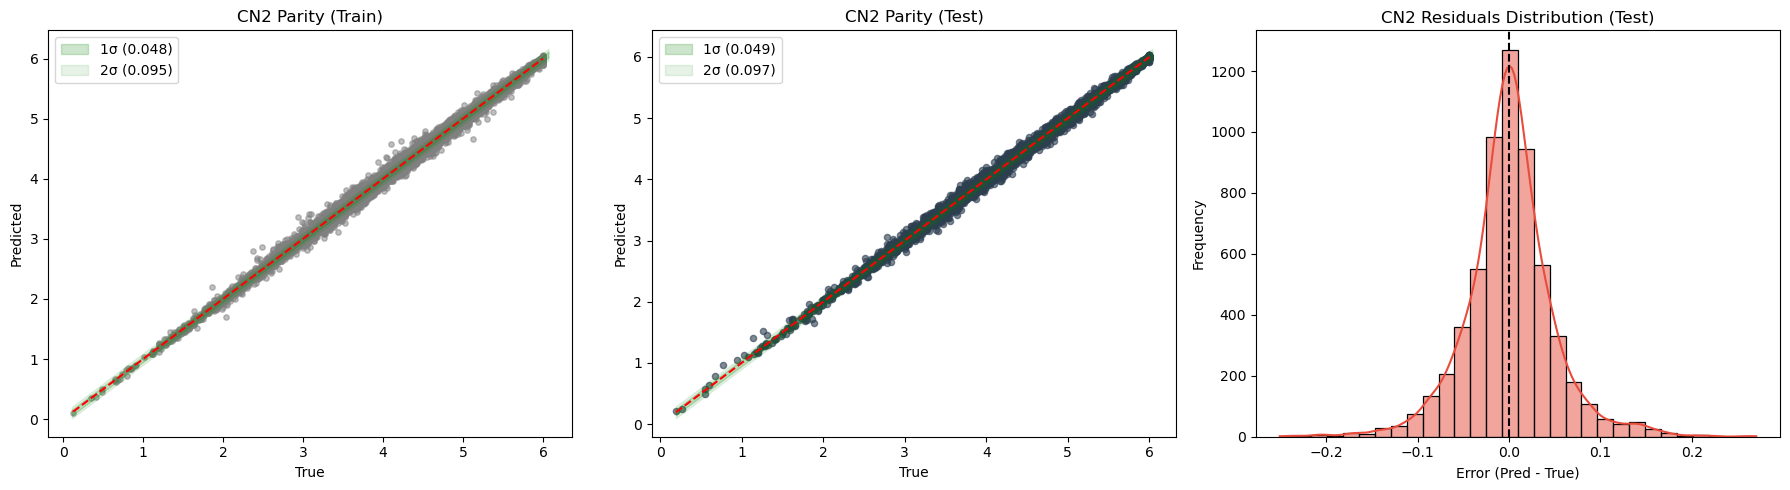


🚀 Моделирование CN3...


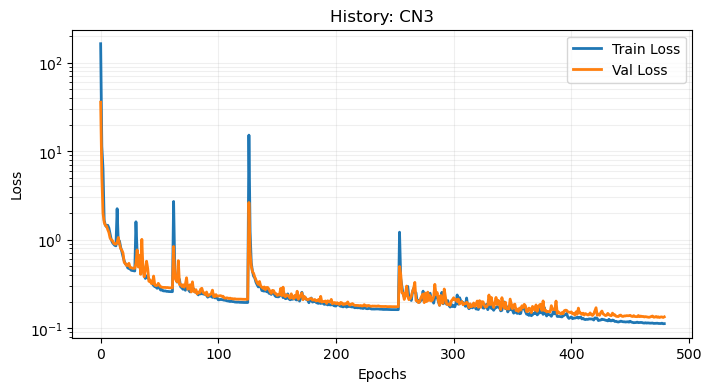

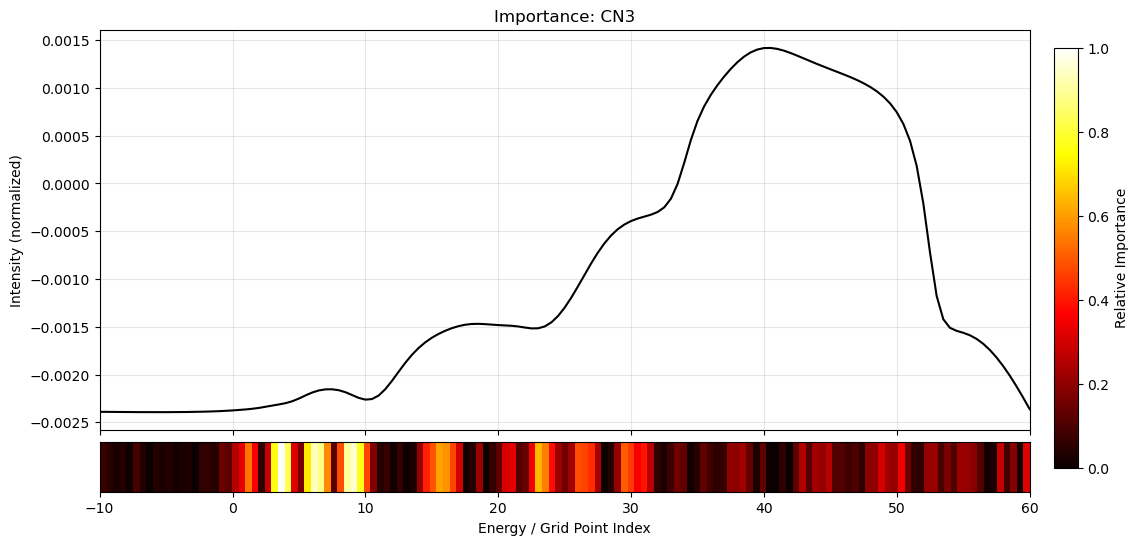

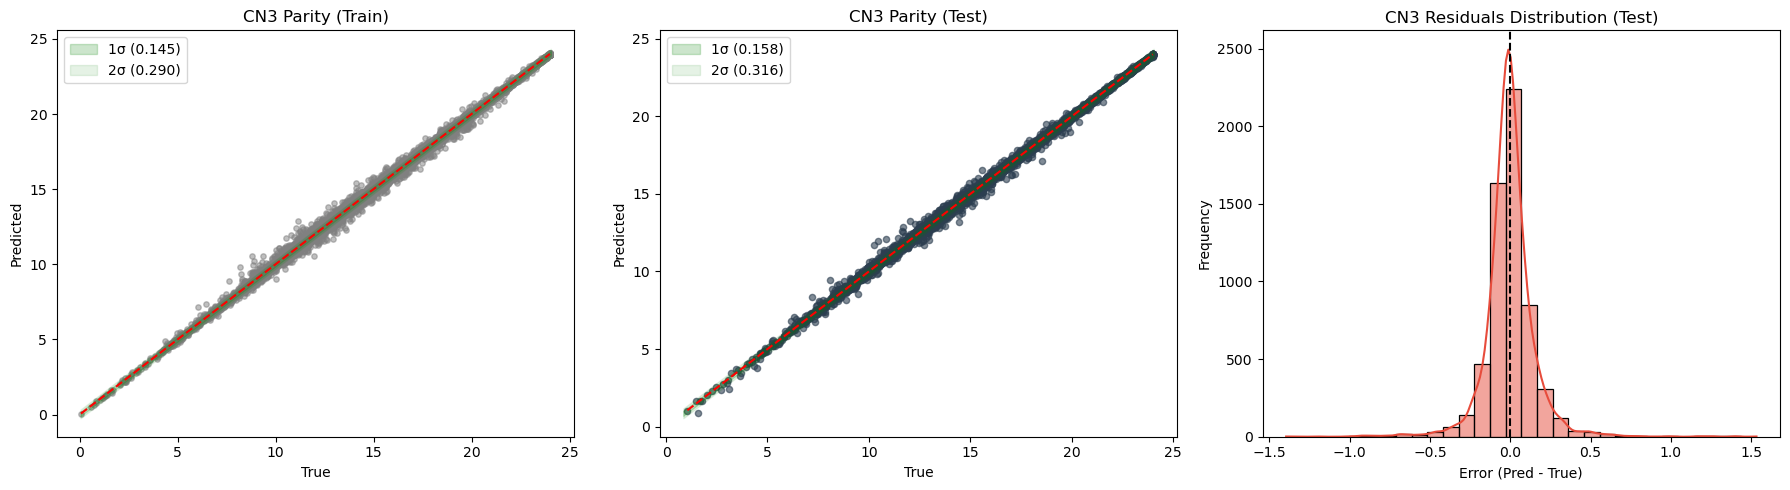


🚀 Моделирование CN4...


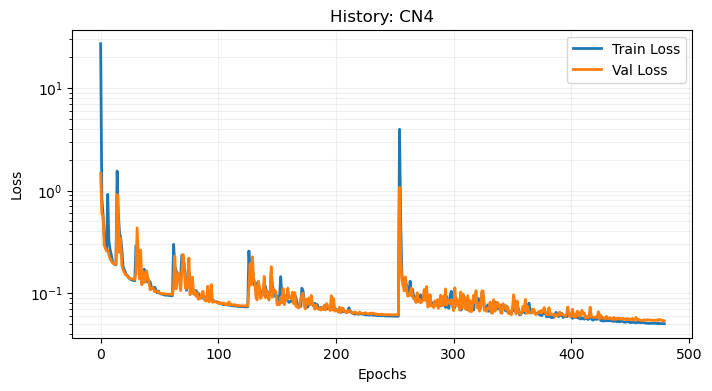

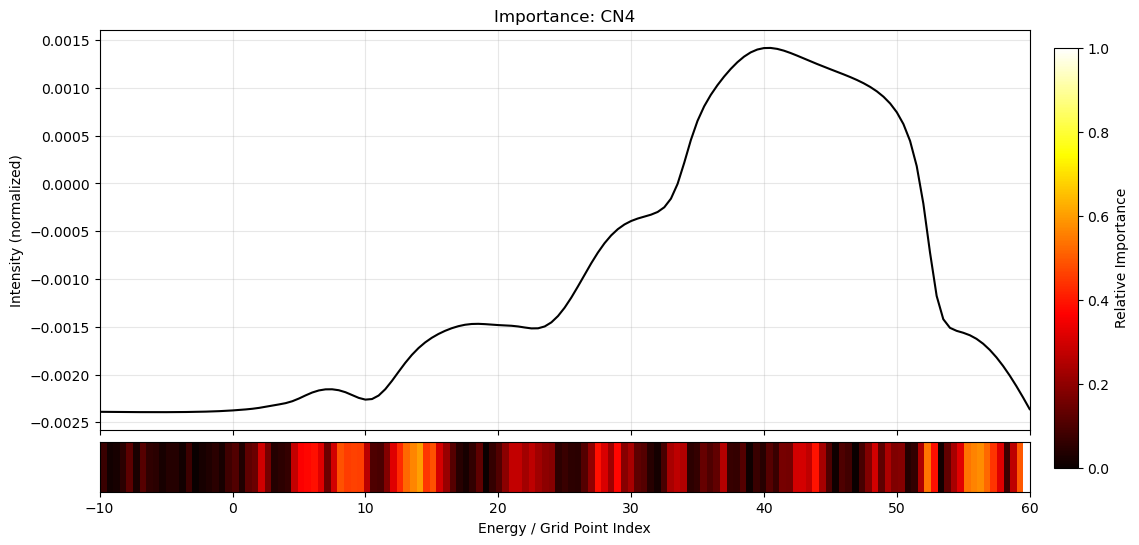

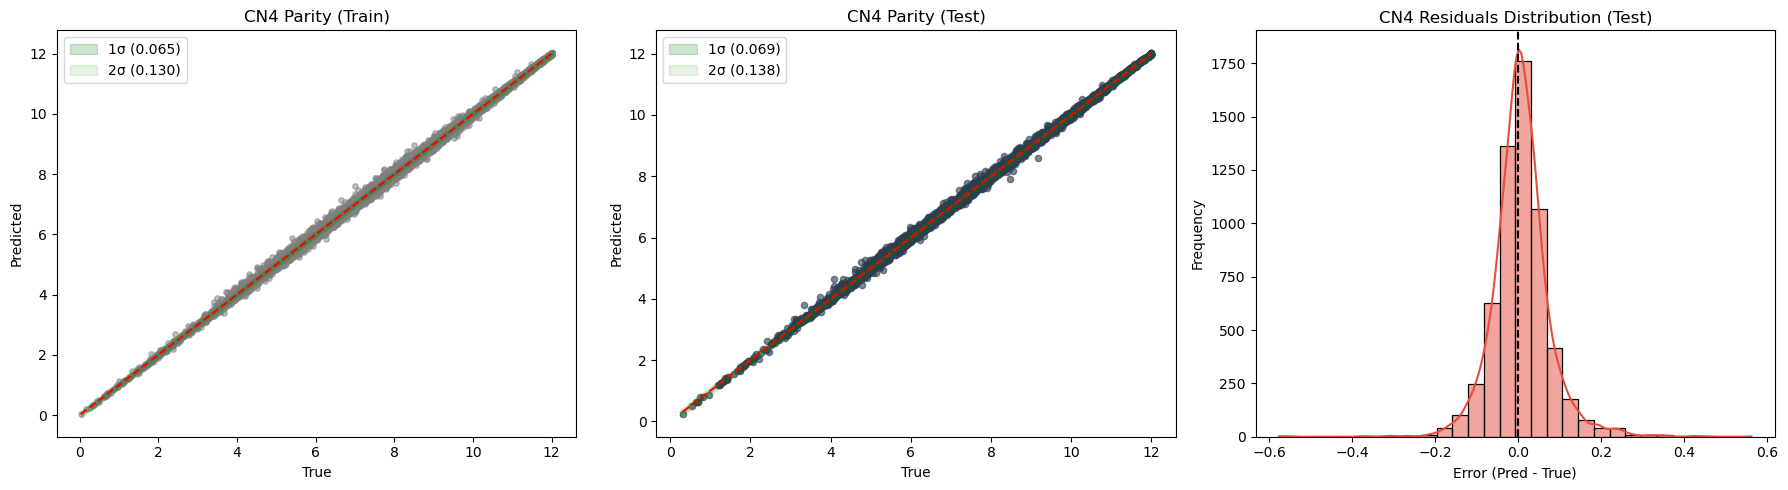


🚀 Моделирование CN5...


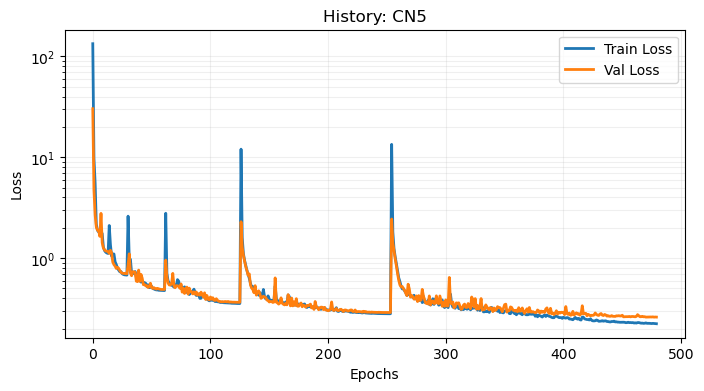

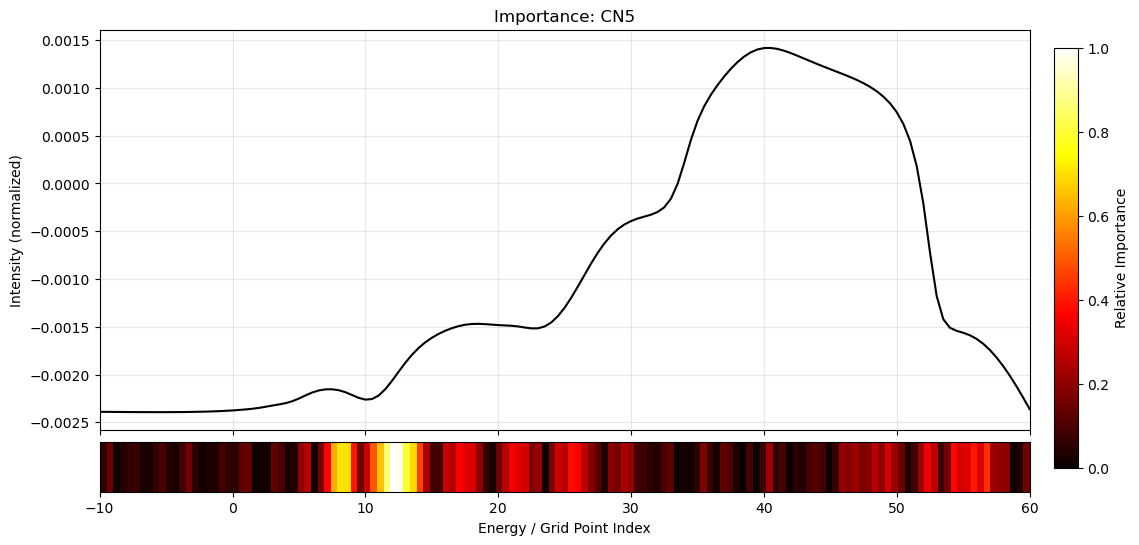

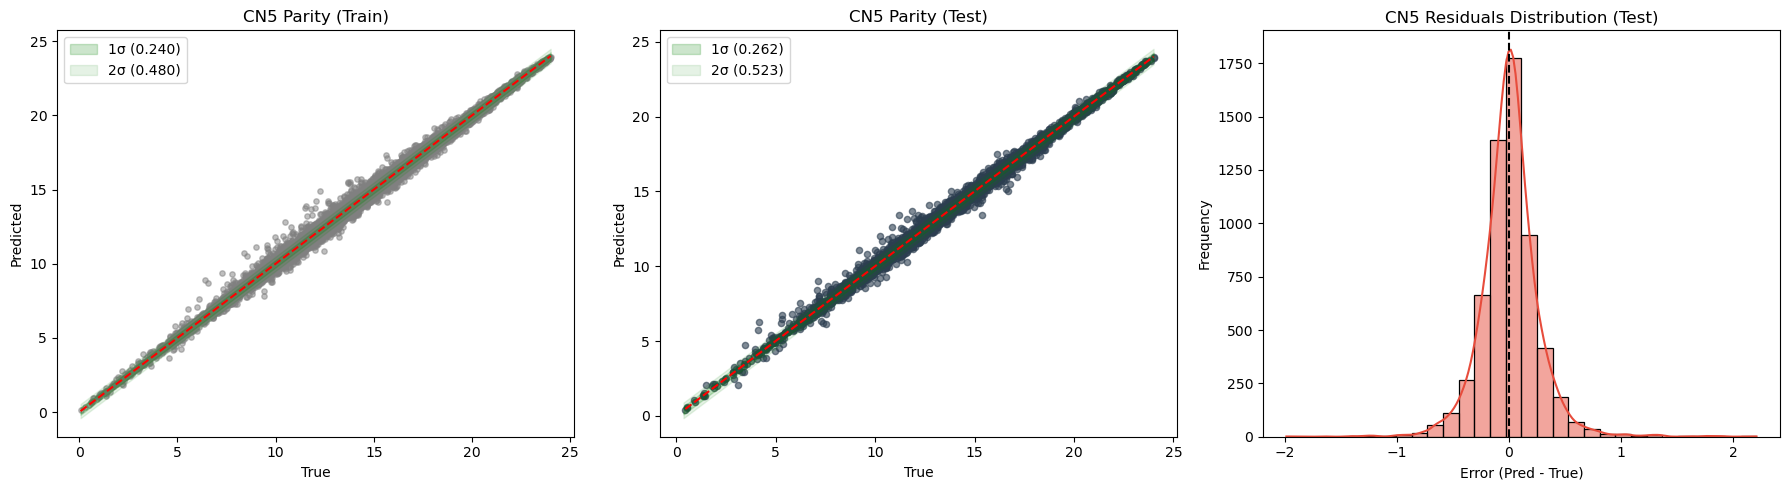


🚀 Моделирование CN6...


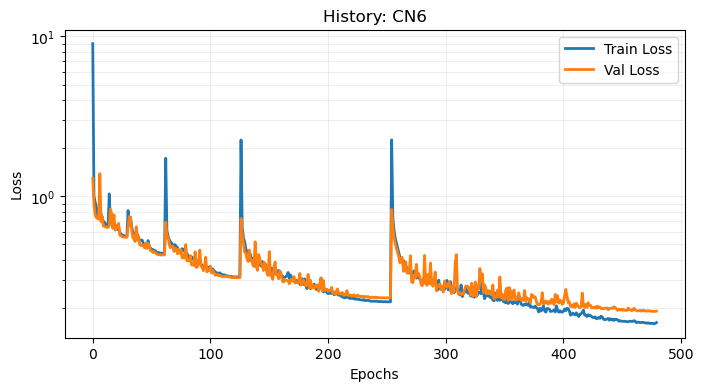

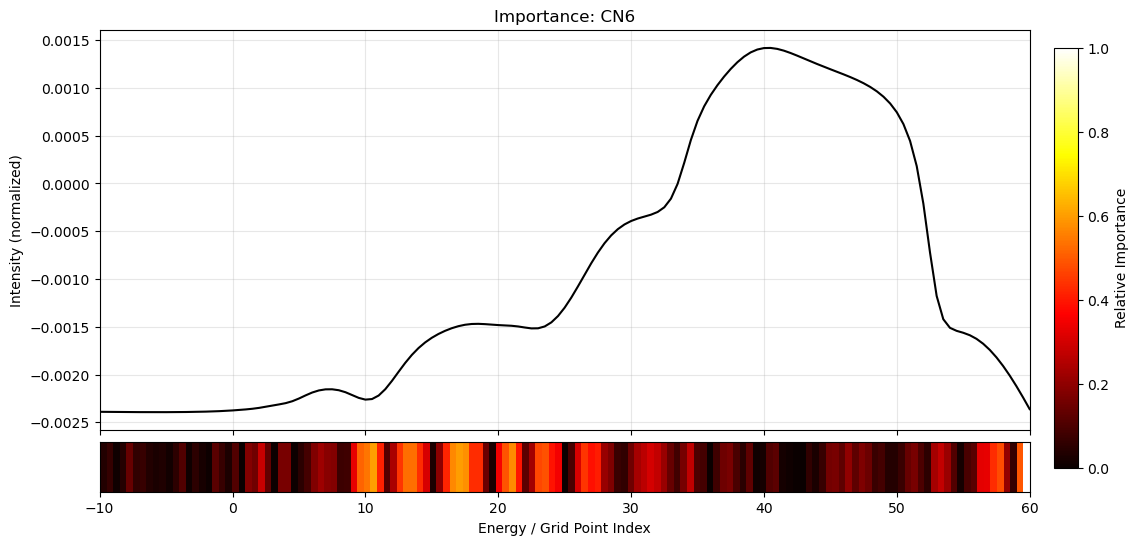

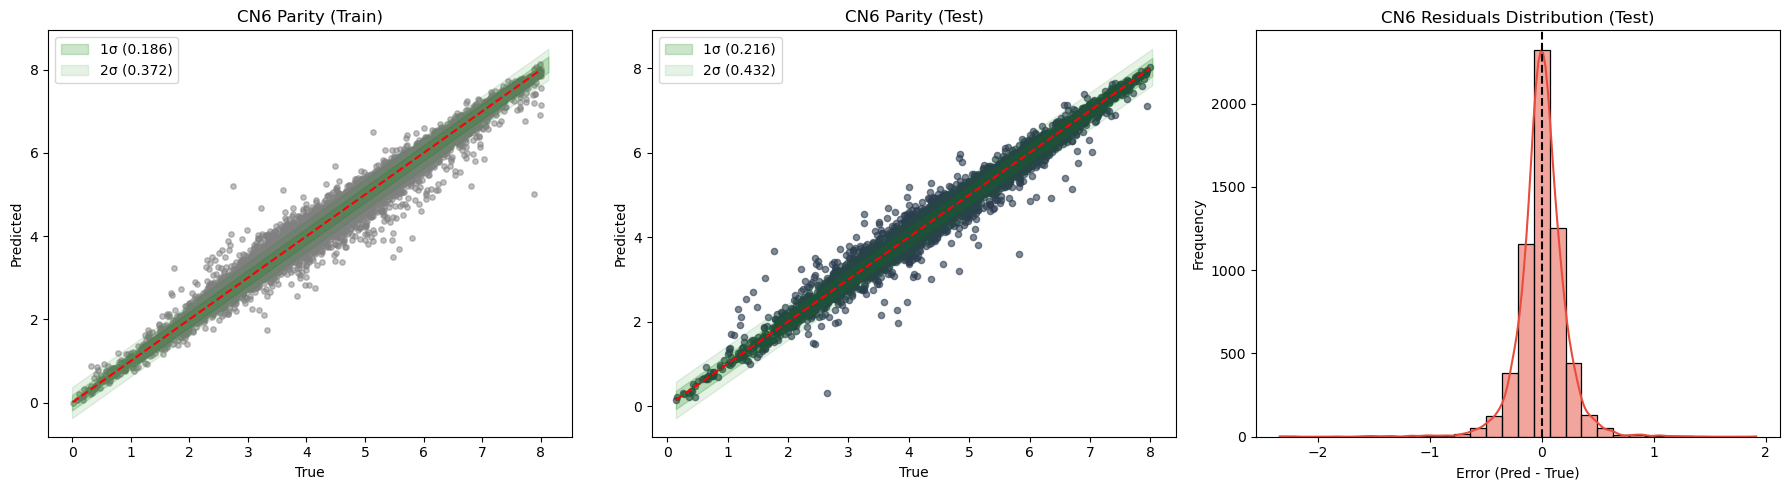


🚀 Моделирование CN7...


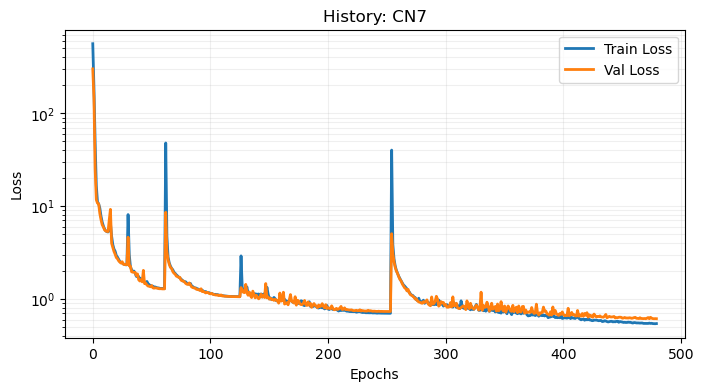

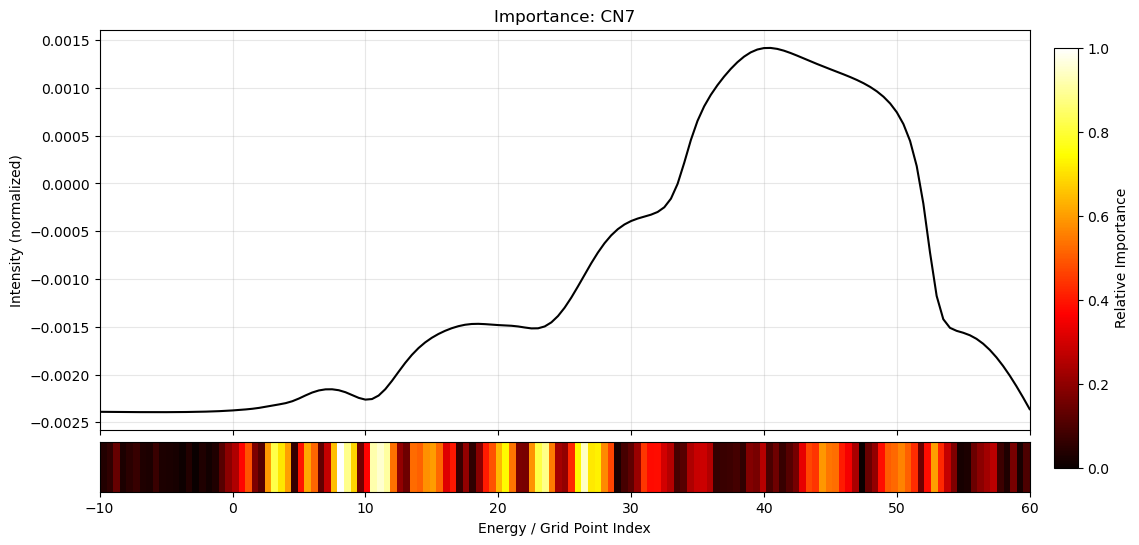

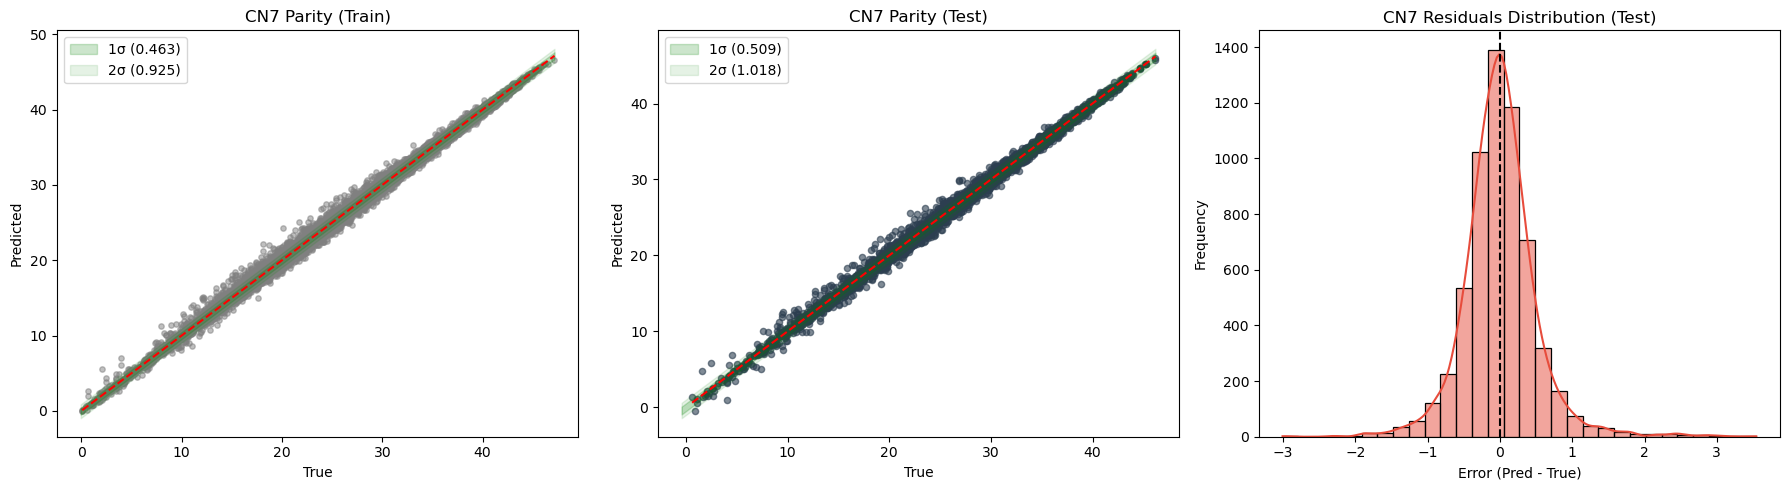


📊 ИТОГОВЫЙ ОТЧЕТ
           R2                  MAE              
Split    test  train    val   test  train    val
Target                                          
CN1    0.9998 0.9998 0.9997 0.0221 0.0218 0.0223
CN2    0.9978 0.9979 0.9975 0.0345 0.0328 0.0352
CN3    0.9986 0.9988 0.9983 0.1003 0.0915 0.1037
CN4    0.9989 0.9990 0.9989 0.0484 0.0453 0.0487
CN5    0.9956 0.9962 0.9952 0.1809 0.1649 0.1865
CN6    0.9744 0.9810 0.9748 0.1440 0.1235 0.1443
CN7    0.9956 0.9964 0.9956 0.3555 0.3250 0.3557
CPU times: total: 24min 50s
Wall time: 24min 32s


In [6]:
%%time
save_root = Path('../processed_data/Results/JanisLike/MLP/')  
model = XanesNN_JanisLike(in_dim=IN_DIM)
loader = XANESDataLoader(standardize=STAND)
viz = XANESVisualizer()
nn_wrapper = TorchWrapper(model=model,params=params)
pipeline_nn = XANESPipeline(loader=loader, visualizer=viz, wrapper_instance=nn_wrapper, e_grid=E_GRID)
pipeline_nn.run(paths=paths_JanisLike, save_root=save_root)

### Cценарий1B (NotJanisLike)


🚀 Моделирование CN1...


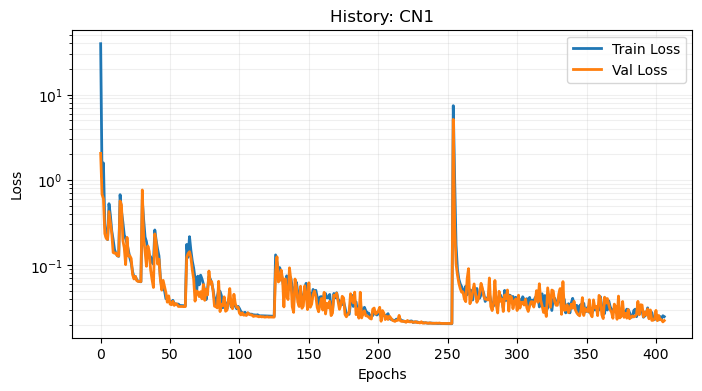

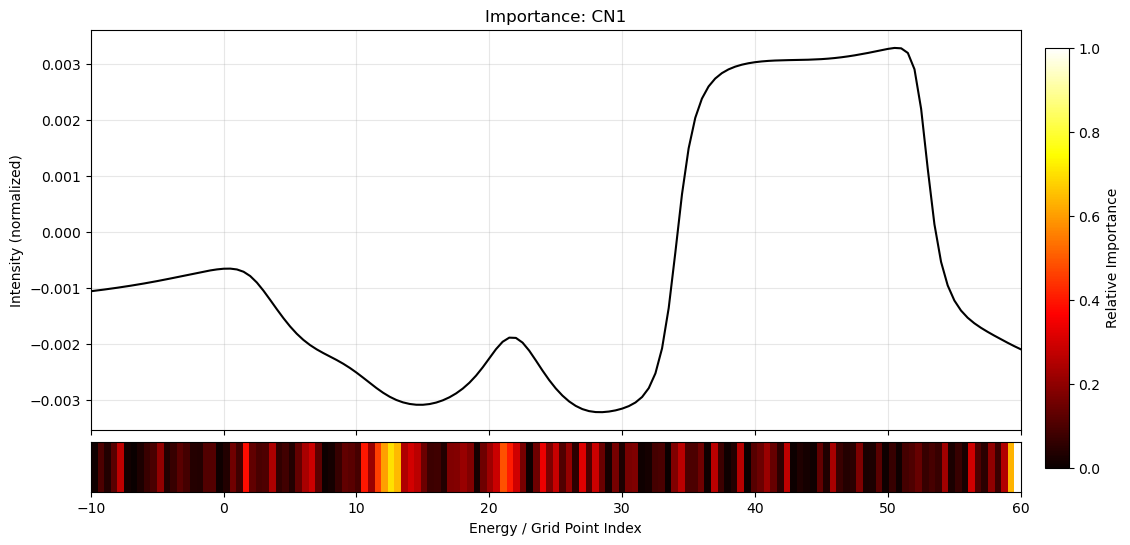

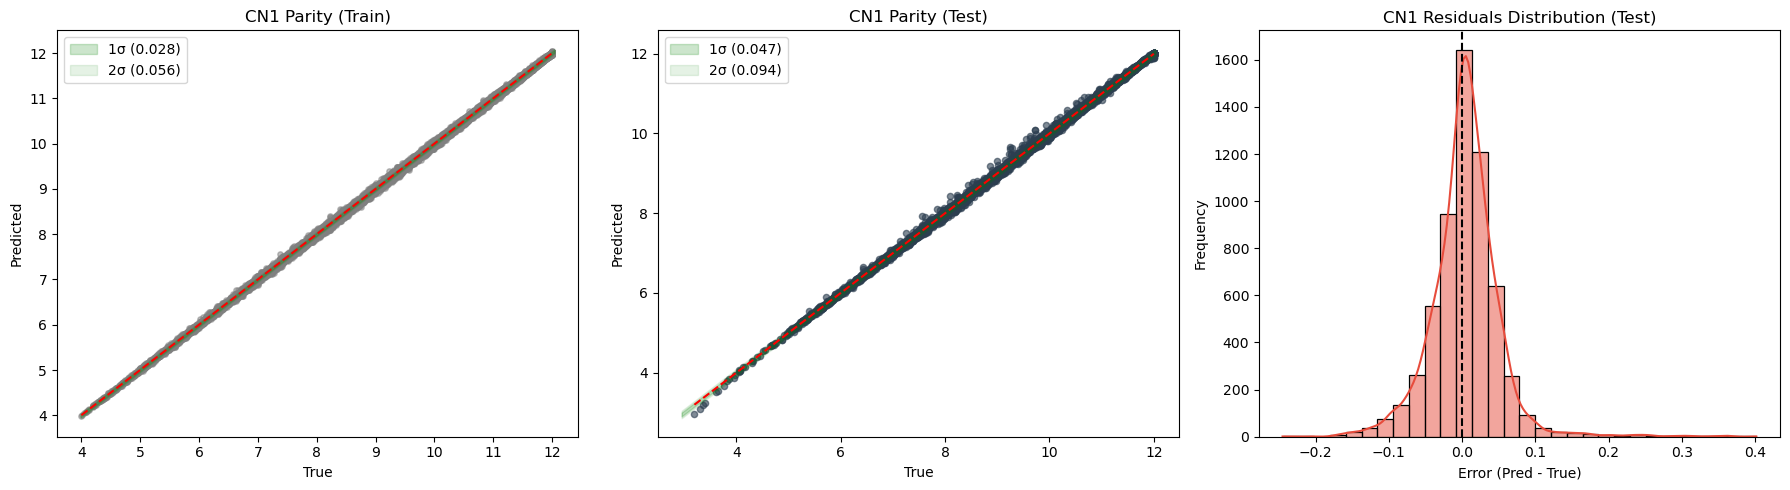


🚀 Моделирование CN2...


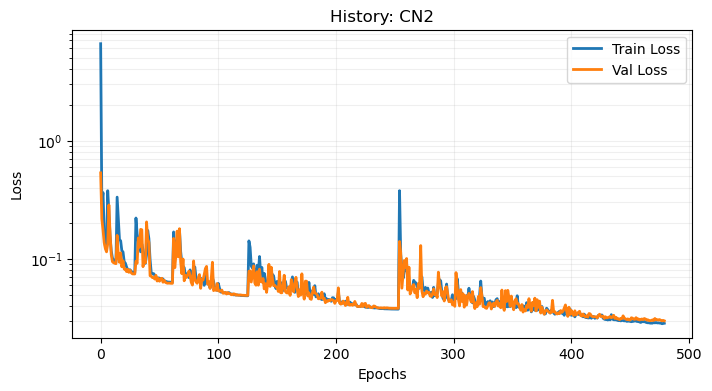

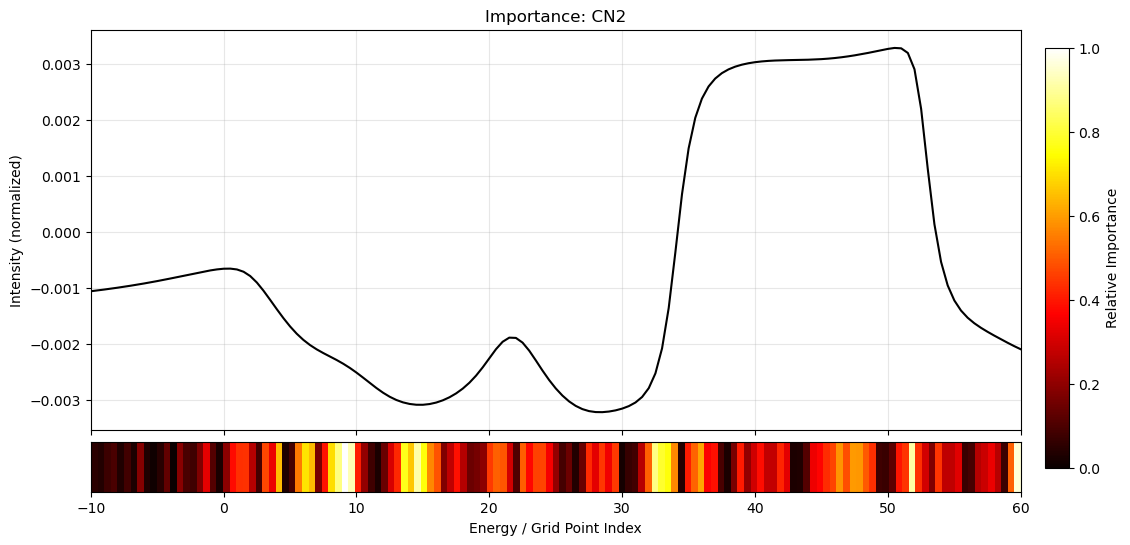

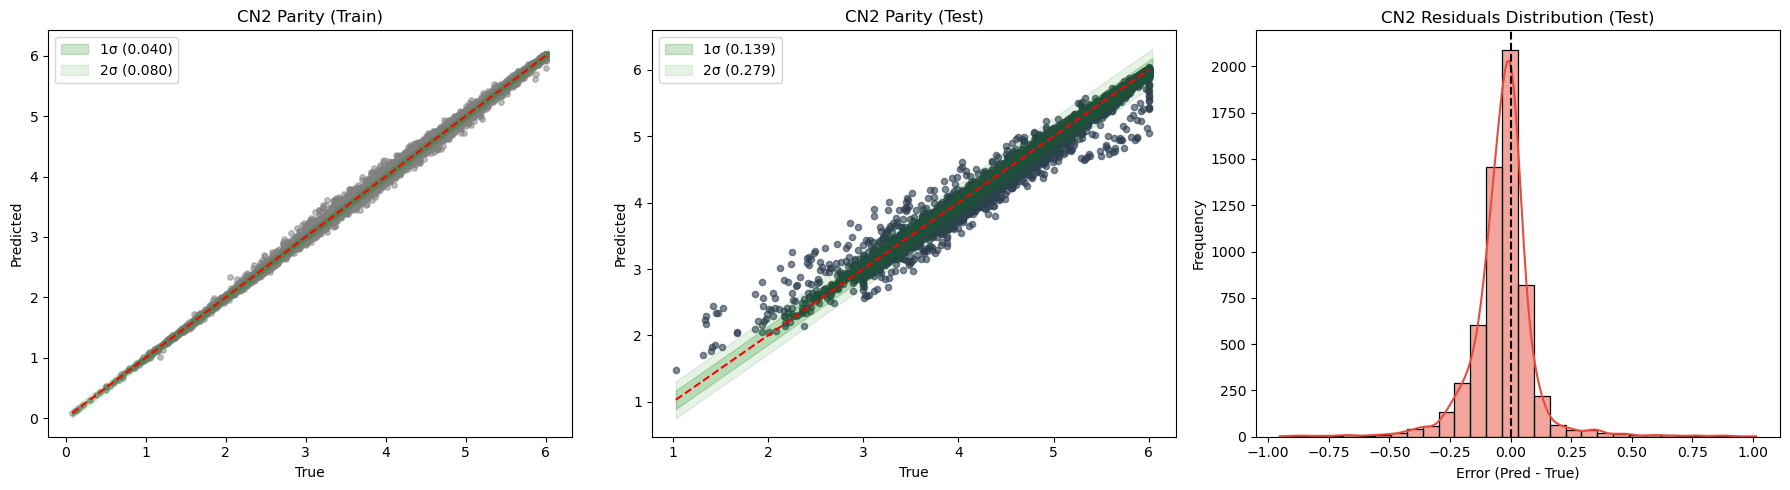


🚀 Моделирование CN3...


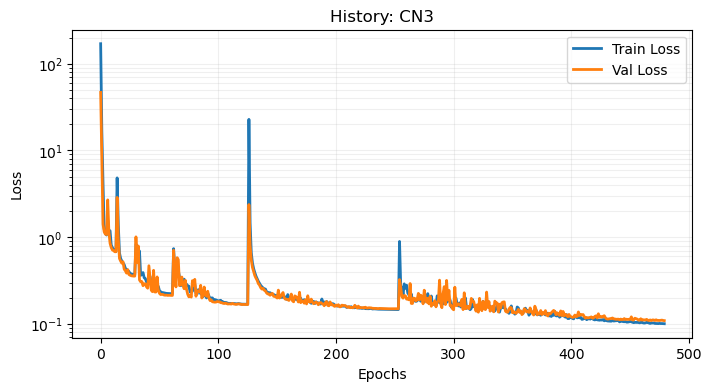

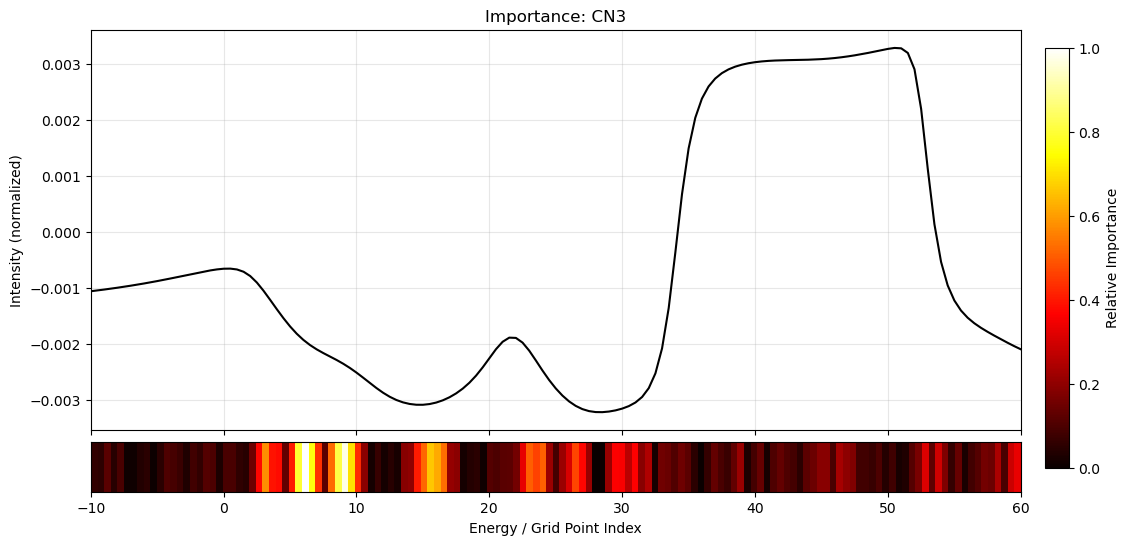

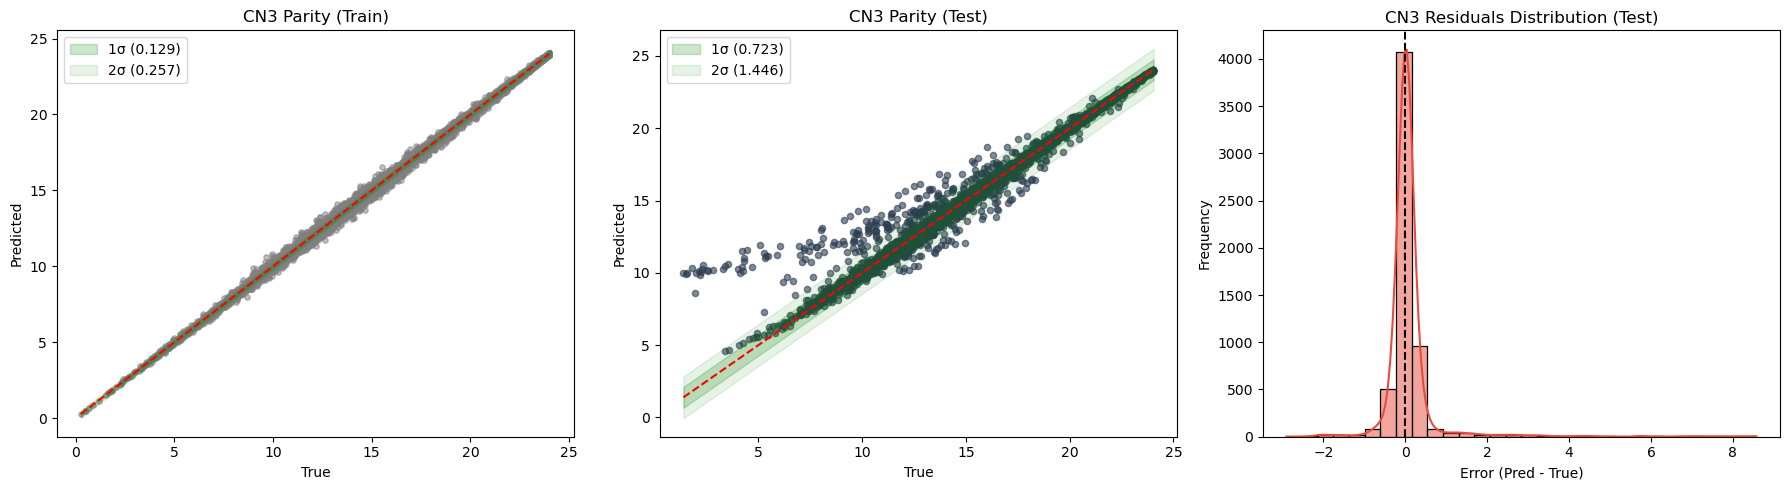


🚀 Моделирование CN4...


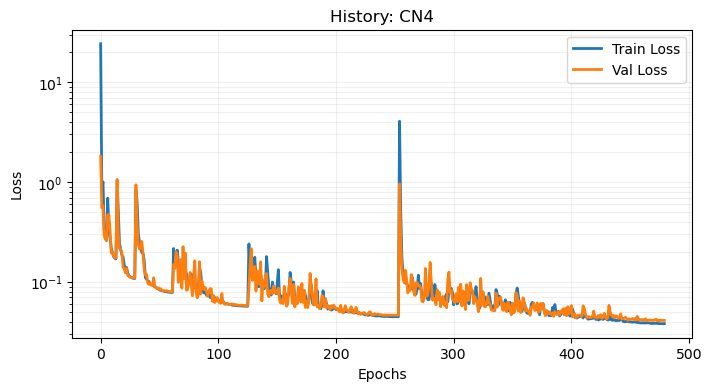

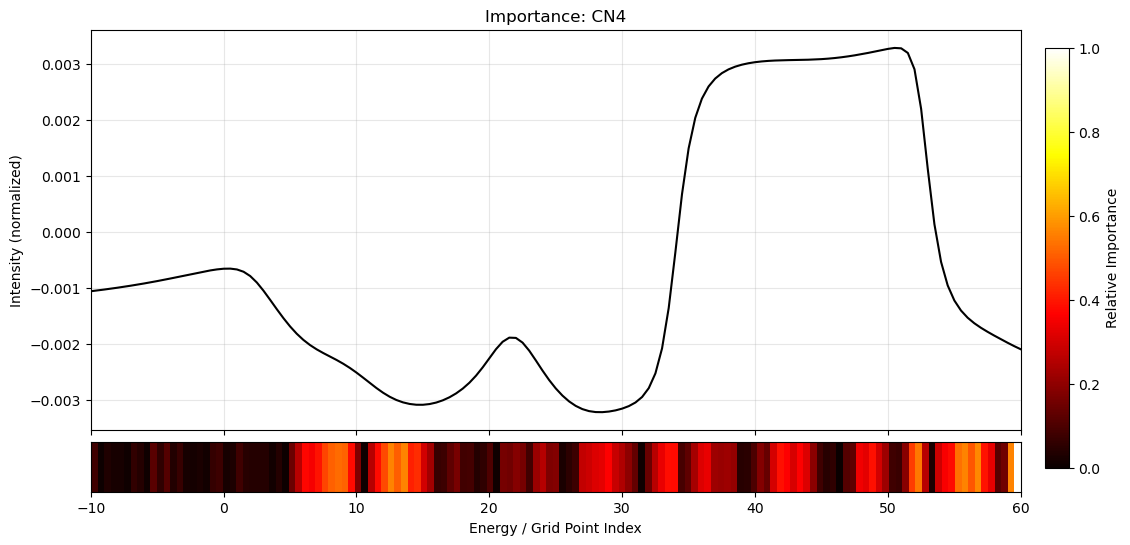

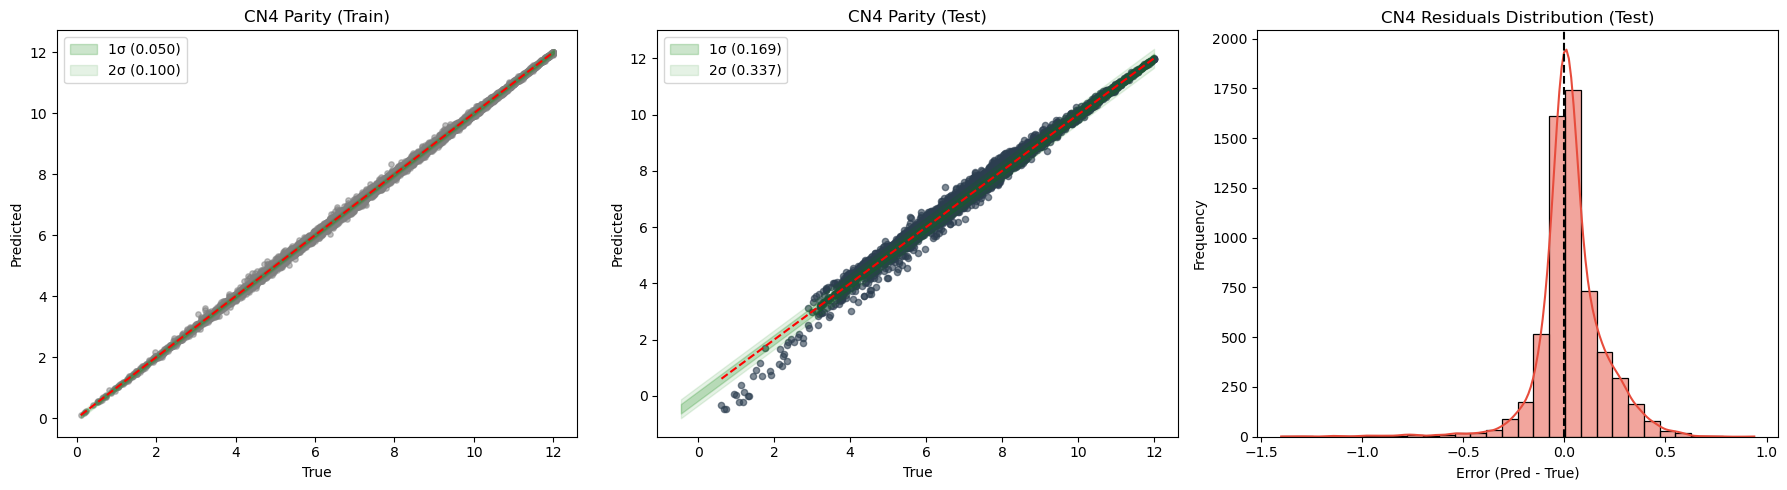


🚀 Моделирование CN5...


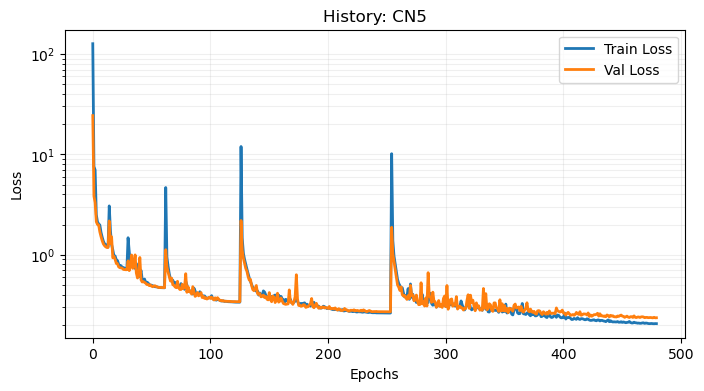

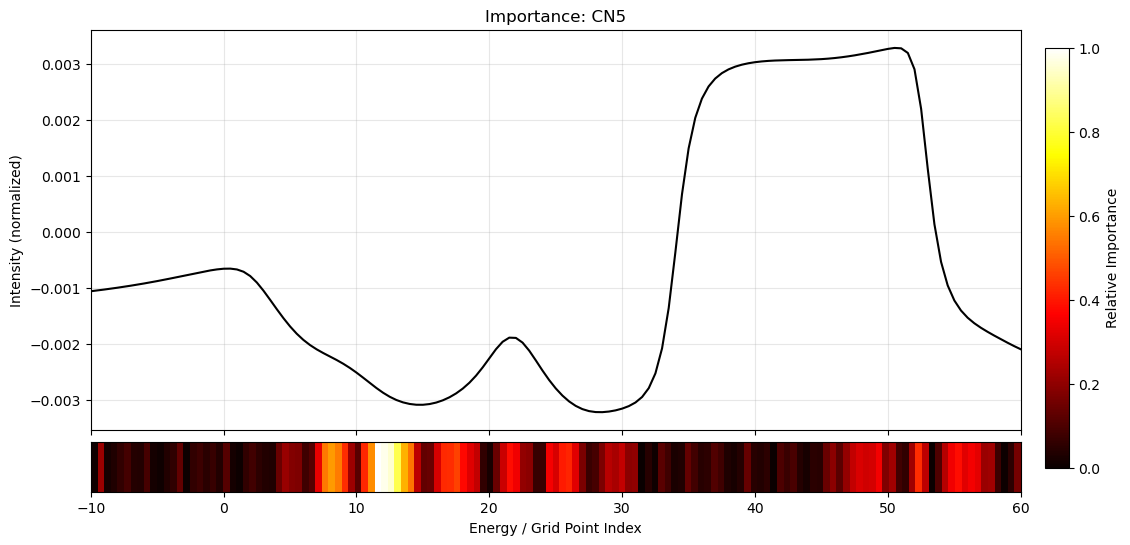

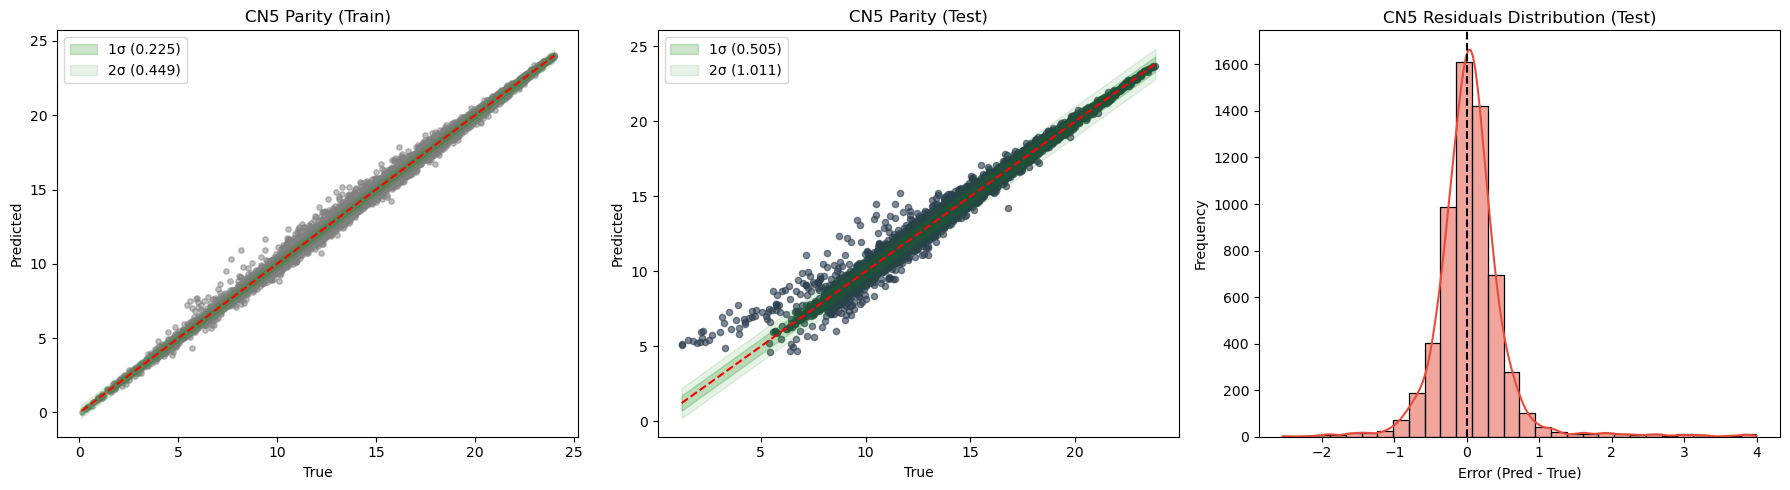


🚀 Моделирование CN6...


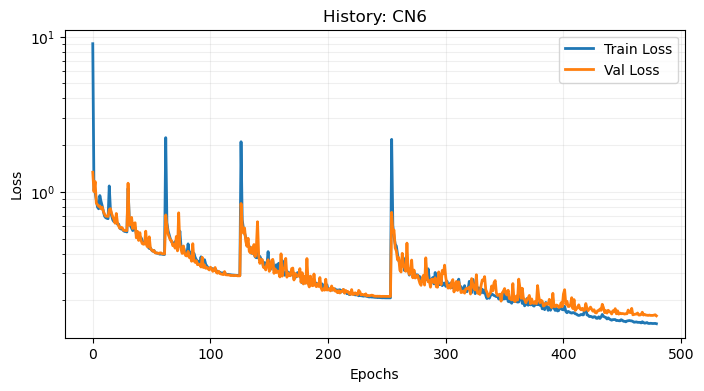

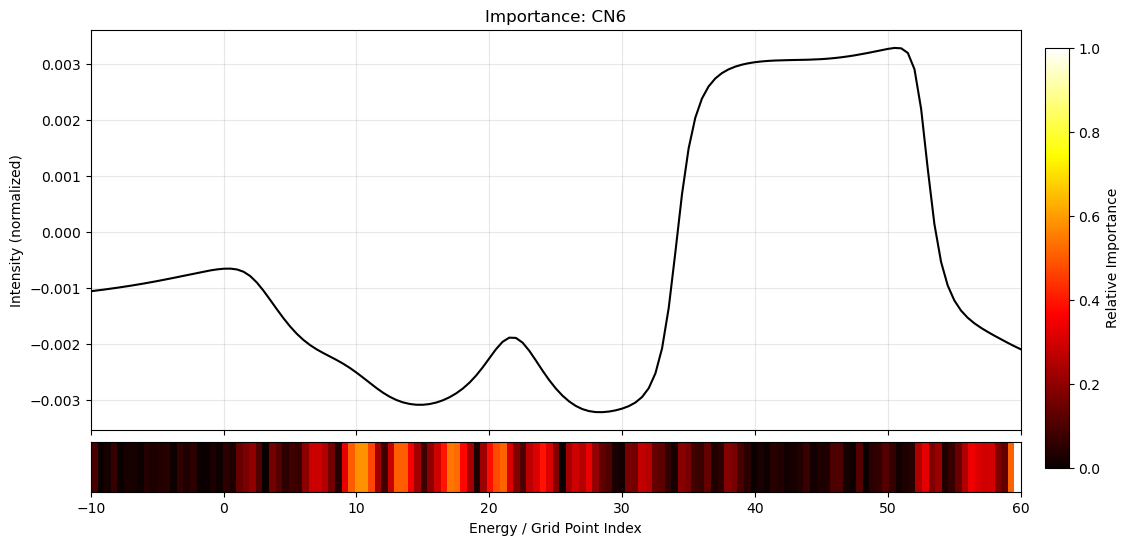

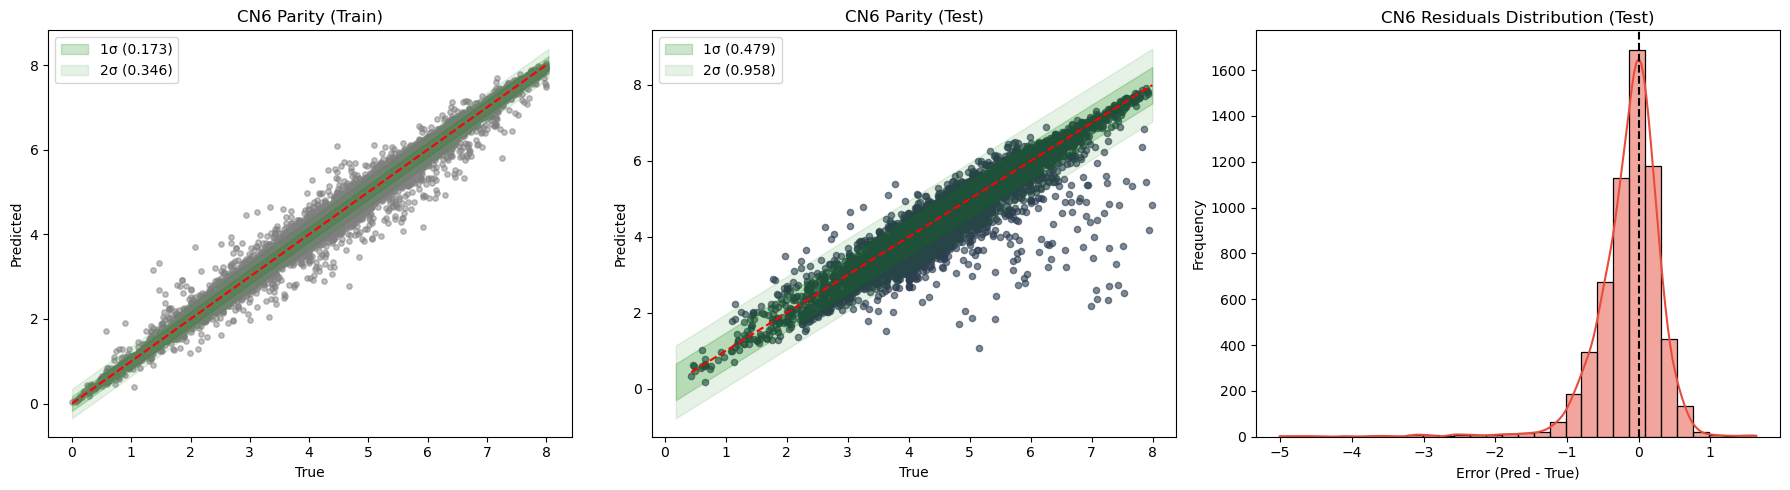


🚀 Моделирование CN7...


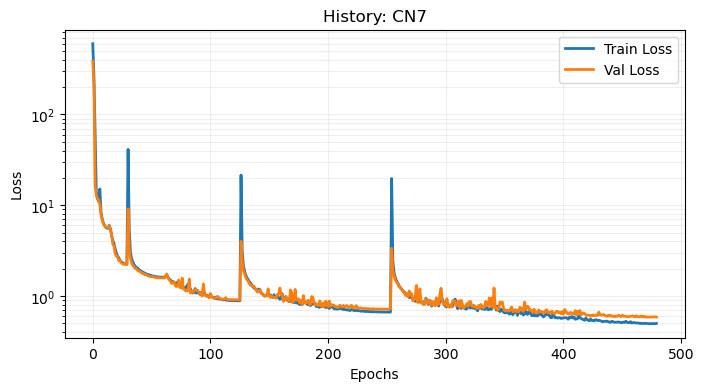

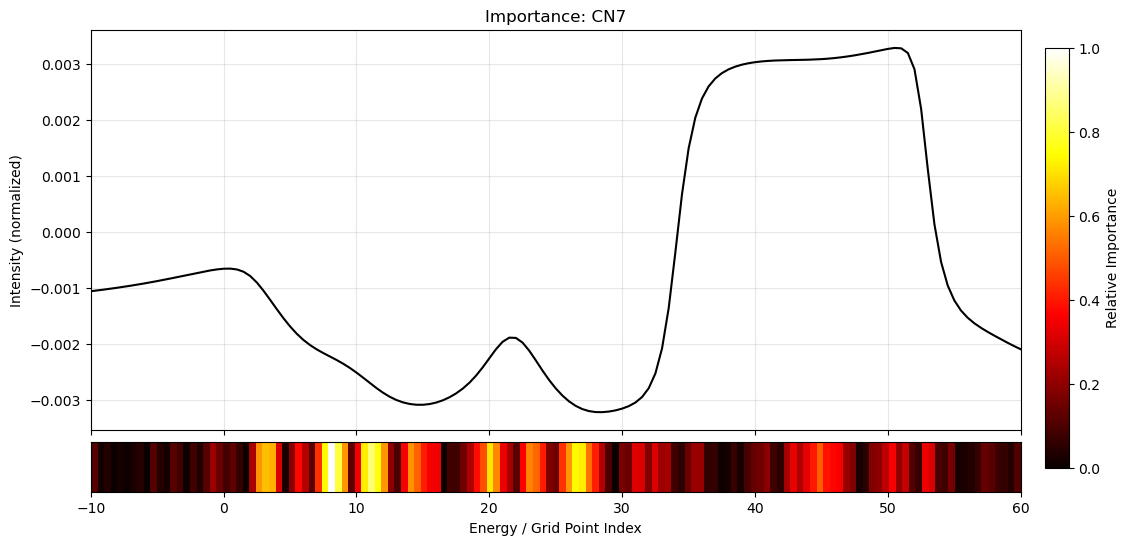

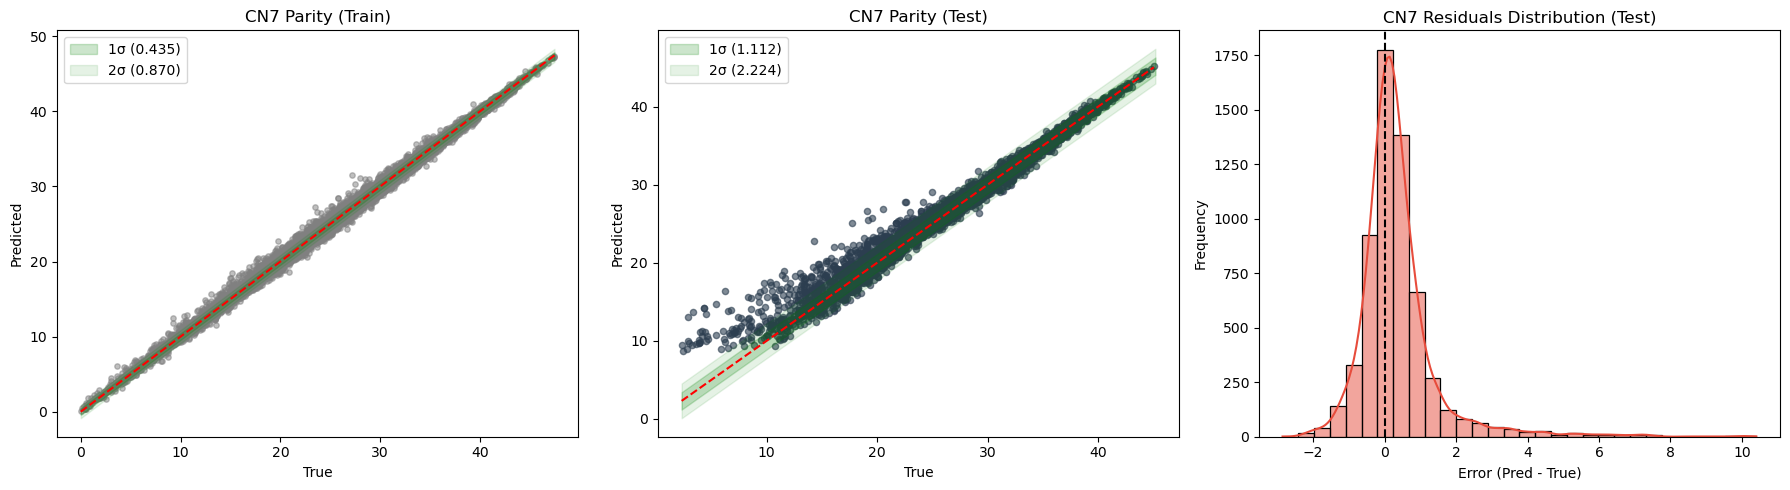


📊 ИТОГОВЫЙ ОТЧЕТ
           R2                  MAE              
Split    test  train    val   test  train    val
Target                                          
CN1    0.9994 0.9998 0.9998 0.0324 0.0198 0.0200
CN2    0.9767 0.9987 0.9985 0.0877 0.0266 0.0282
CN3    0.9663 0.9992 0.9990 0.2697 0.0837 0.0900
CN4    0.9919 0.9995 0.9994 0.1114 0.0353 0.0380
CN5    0.9799 0.9971 0.9964 0.3156 0.1539 0.1714
CN6    0.8285 0.9862 0.9840 0.3186 0.1104 0.1235
CN7    0.9723 0.9972 0.9964 0.6862 0.3054 0.3450
CPU times: total: 25min 23s
Wall time: 24min 54s


In [7]:
%%time
save_root = Path('../processed_data/Results/NotJanisLike/MLP/')  
model = XanesNN_JanisLike(in_dim=IN_DIM)
loader = XANESDataLoader(standardize=STAND)
viz = XANESVisualizer()
nn_wrapper = TorchWrapper(model=model,params=params)
pipeline_nn = XANESPipeline(loader=loader, visualizer=viz, wrapper_instance=nn_wrapper, e_grid=E_GRID)
pipeline_nn.run(paths=paths_NotJanisLike, save_root=save_root)

###  Сценарий 2А No_Strict (Возможна утечка данных)


🚀 Моделирование CN1...


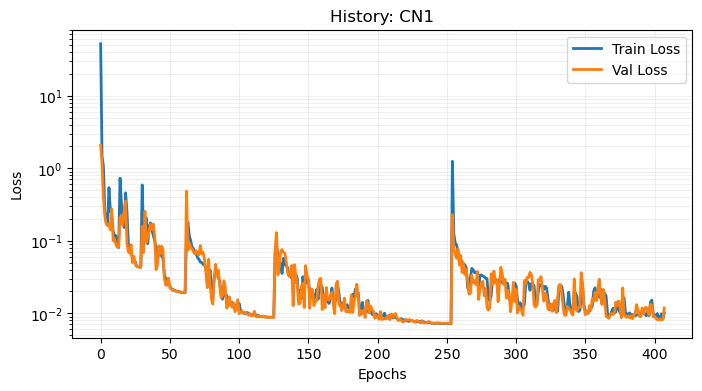

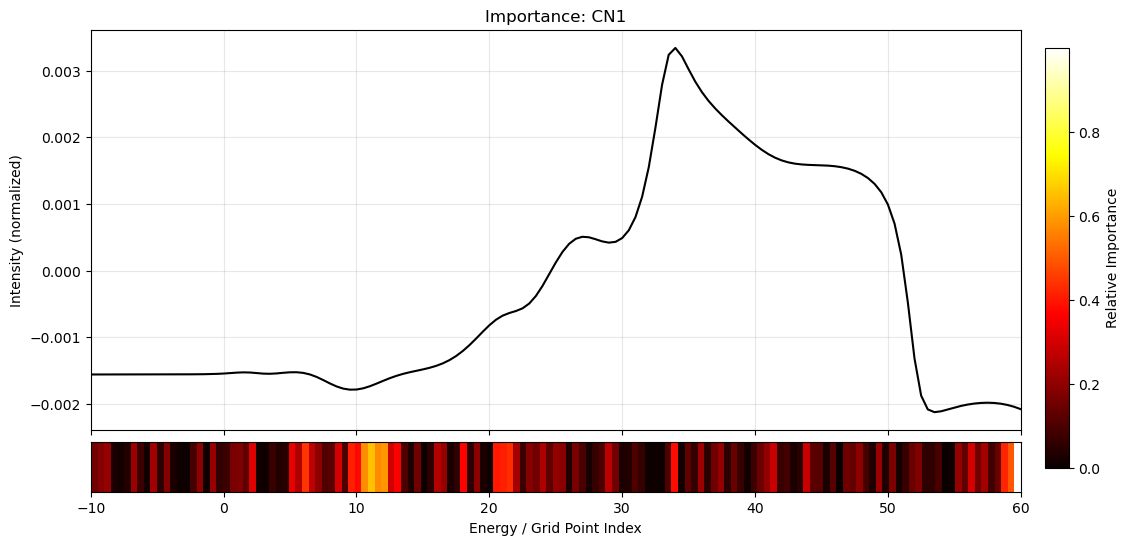

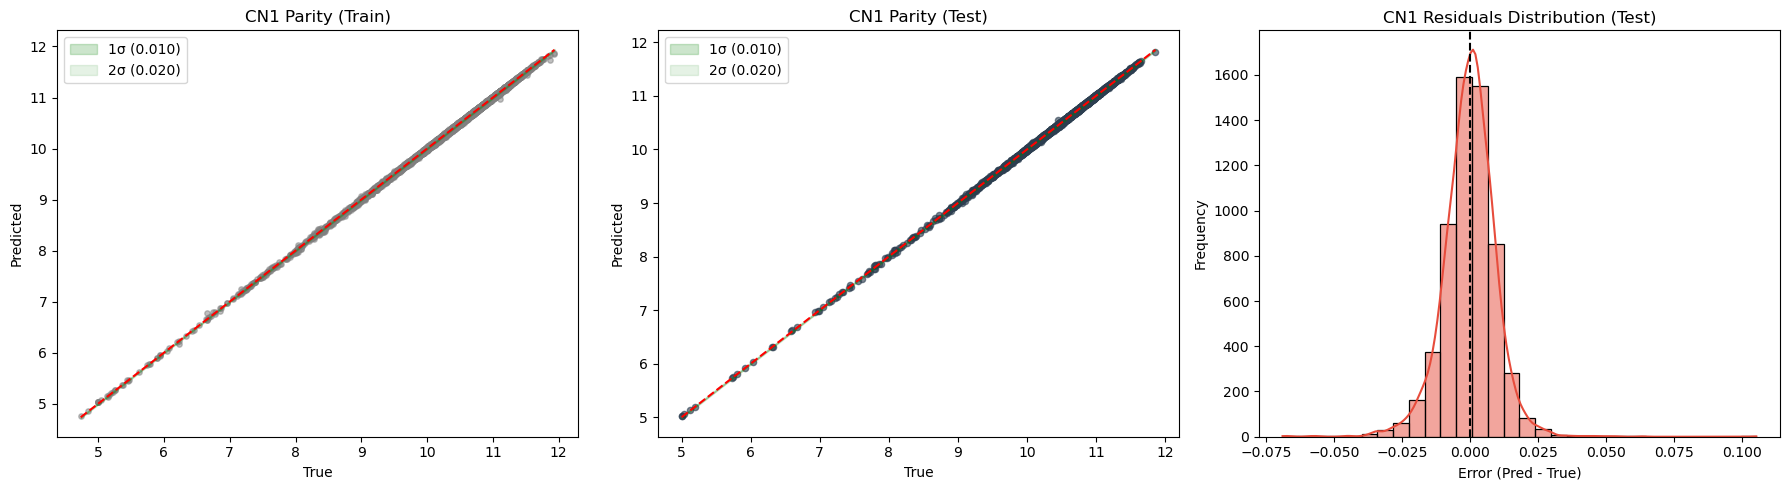


🚀 Моделирование CN2...


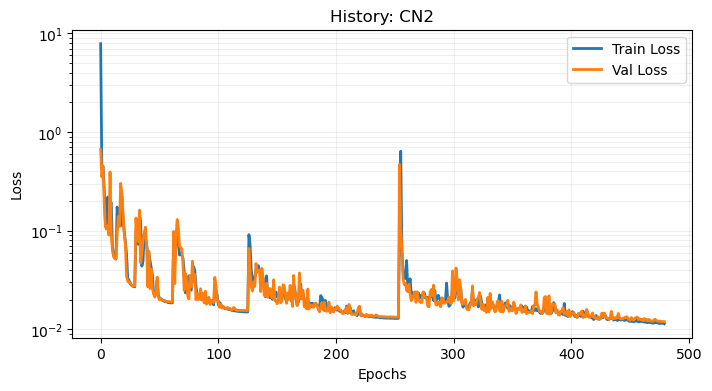

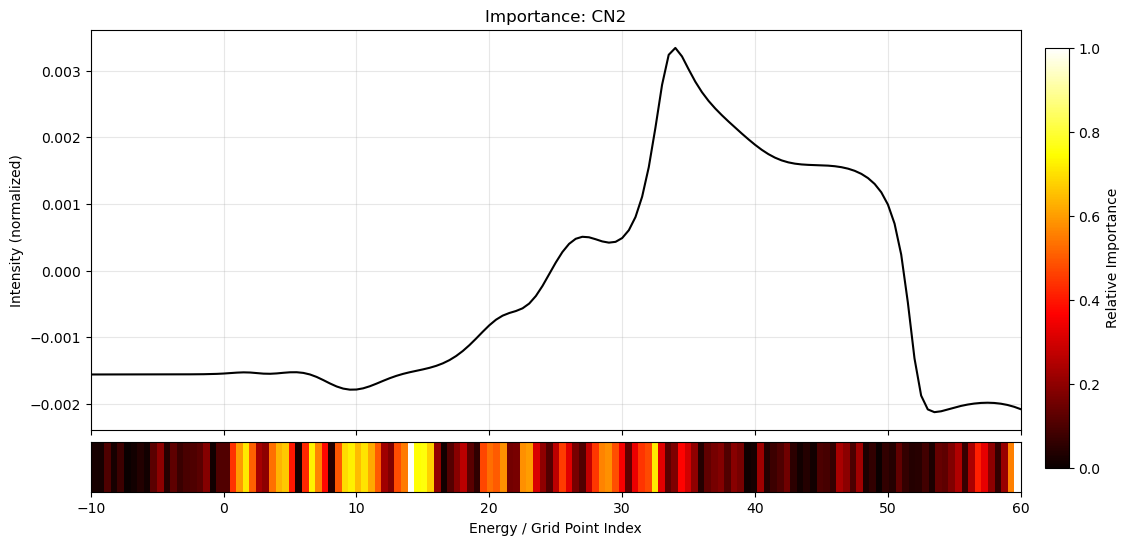

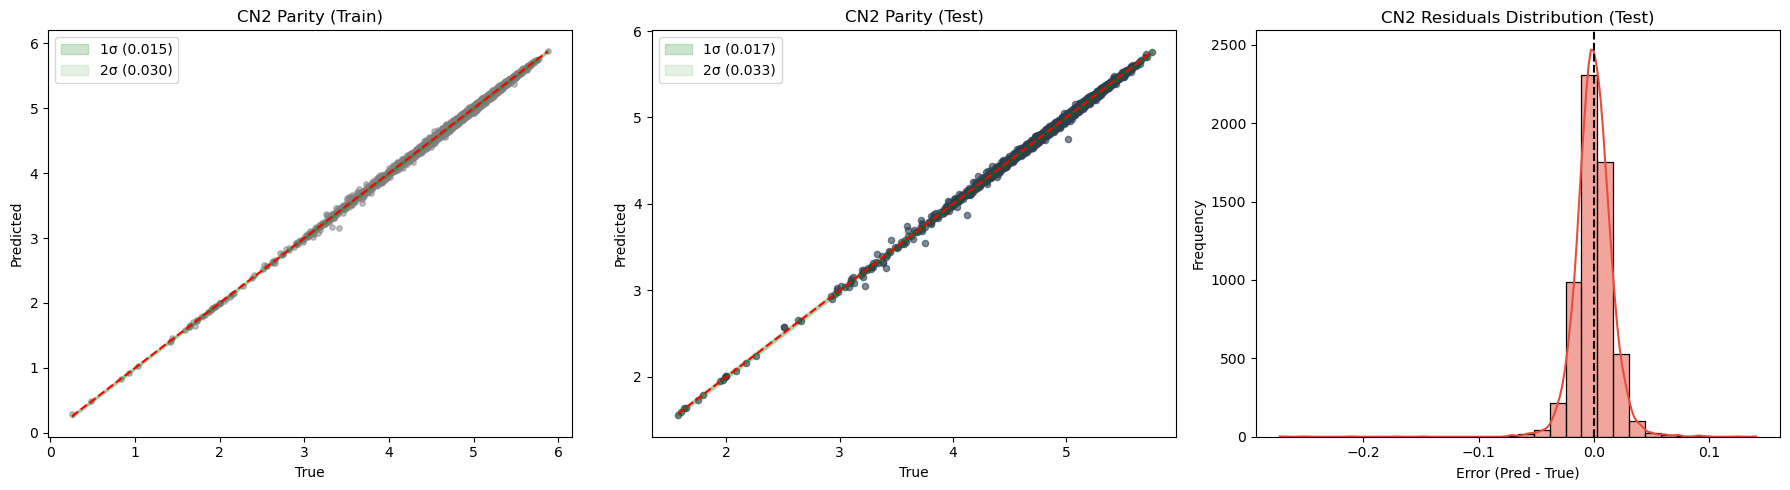


🚀 Моделирование CN3...


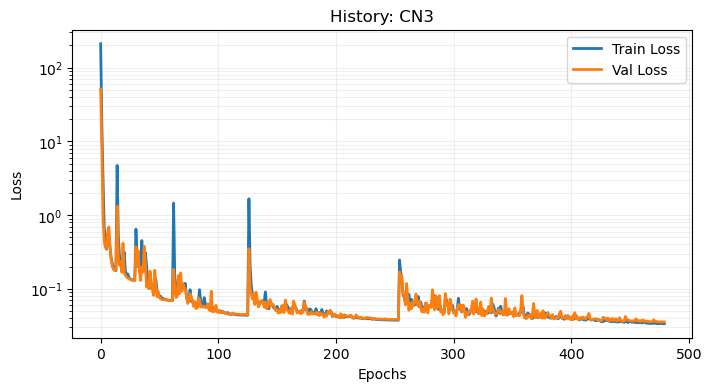

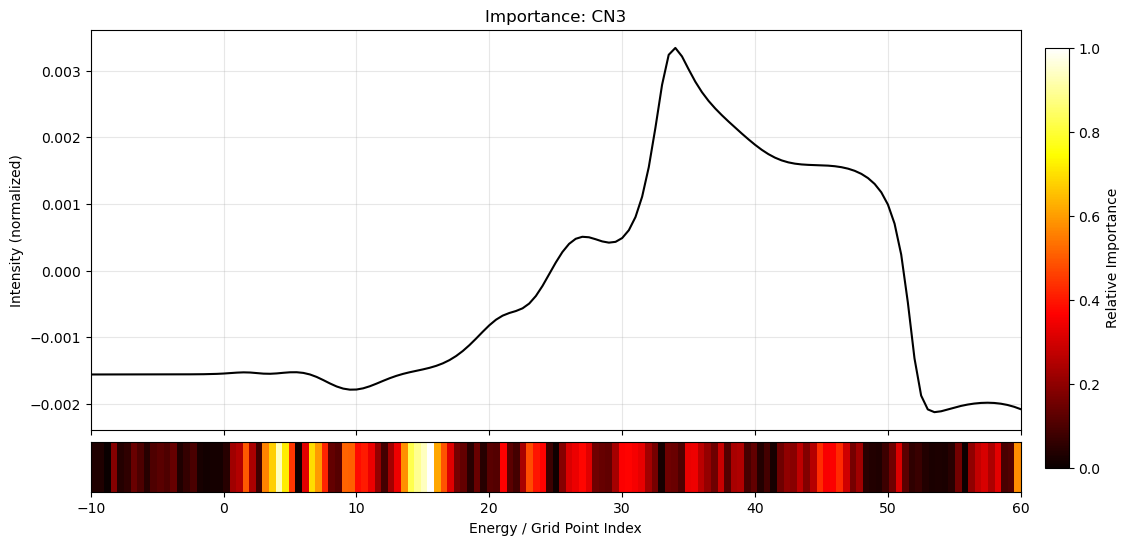

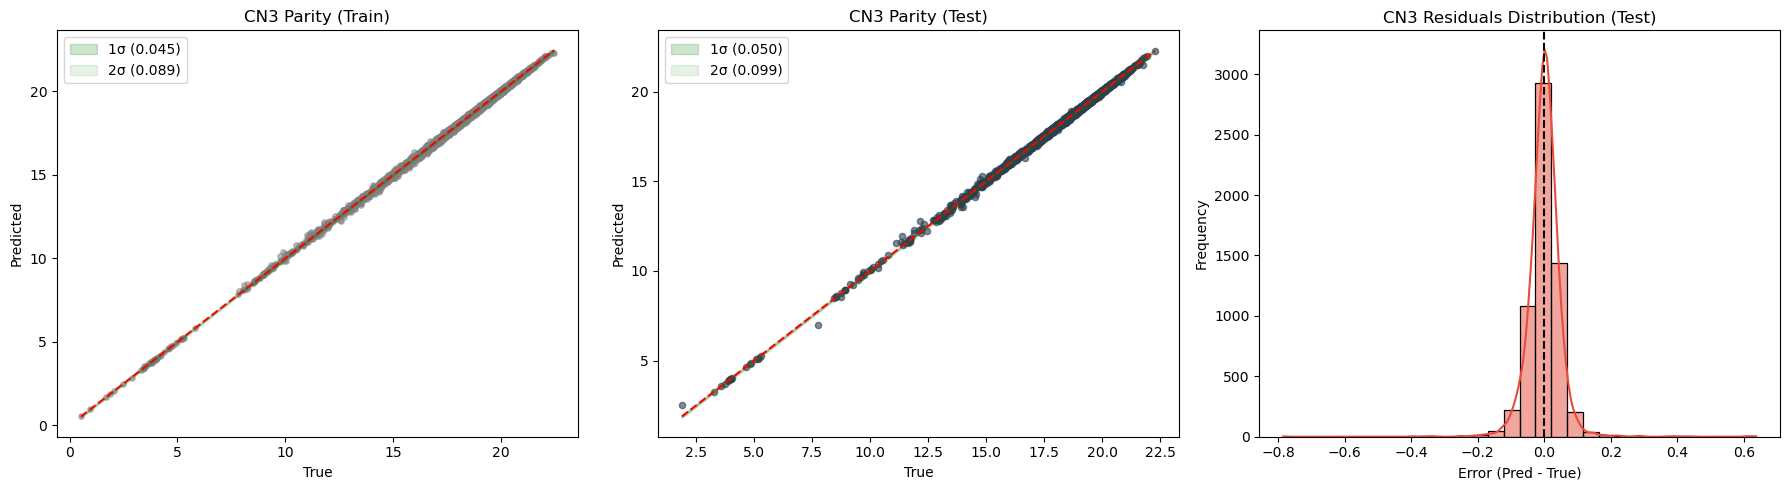


🚀 Моделирование CN4...


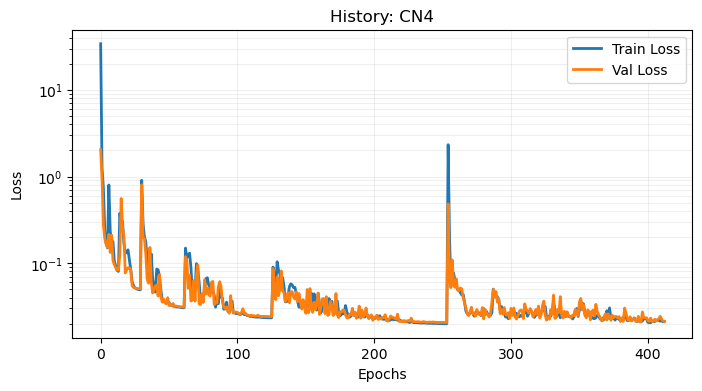

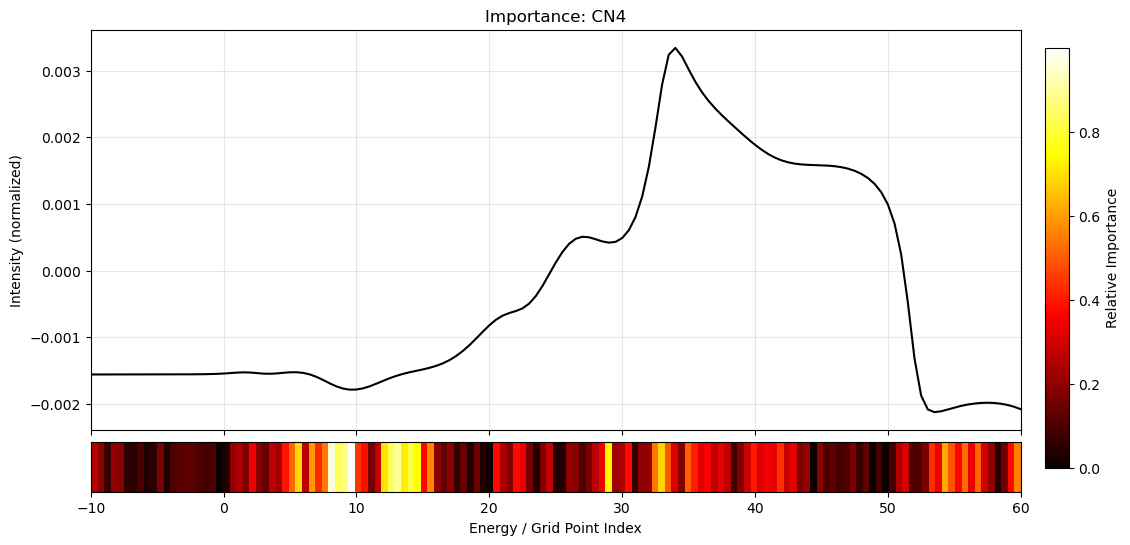

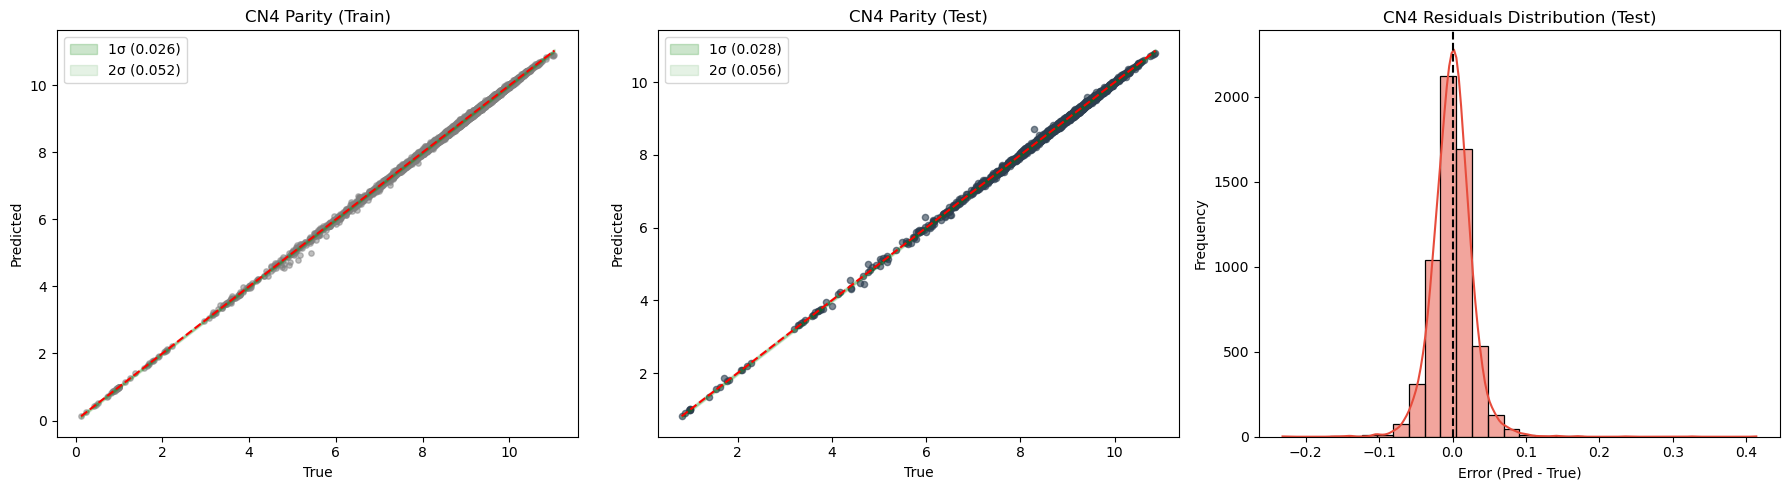


🚀 Моделирование CN5...


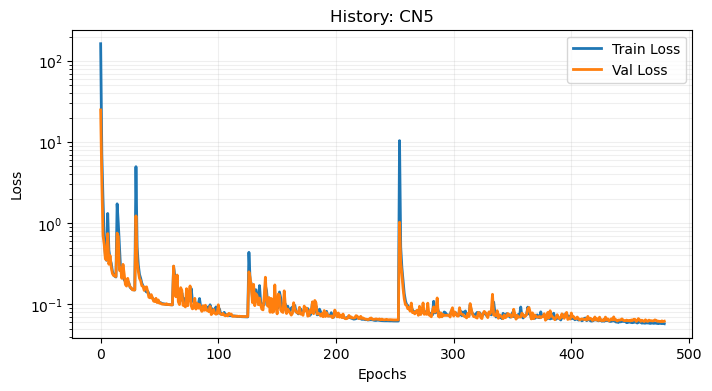

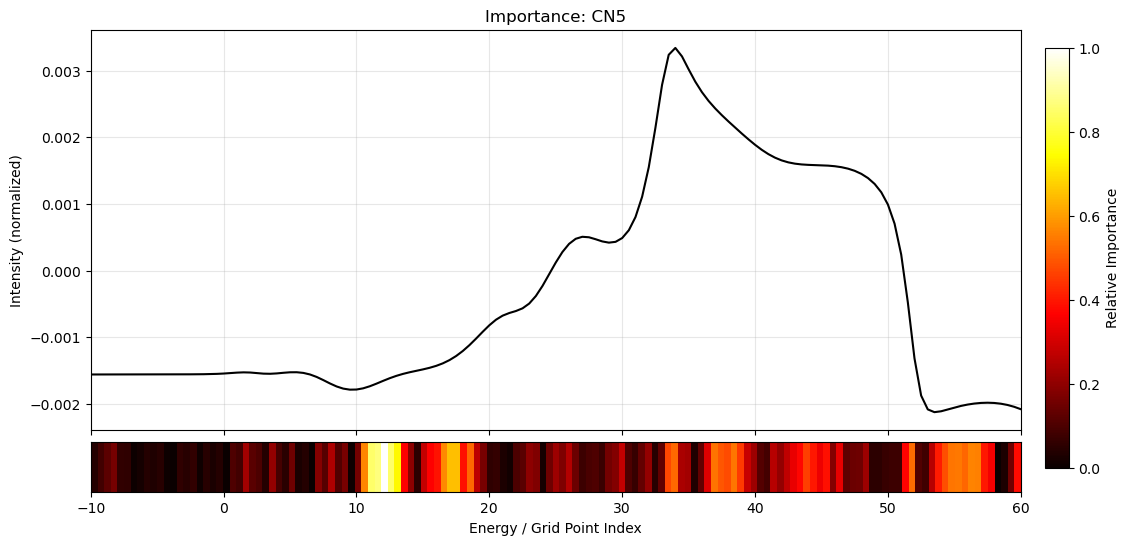

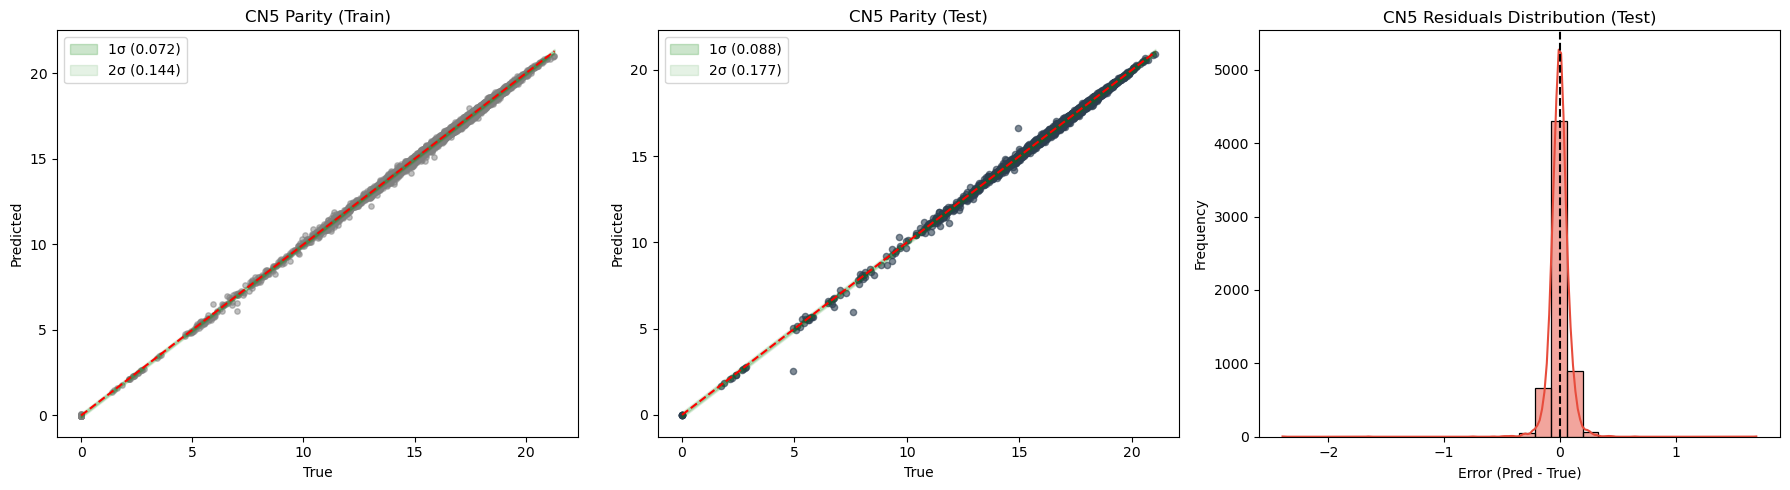


🚀 Моделирование CN6...


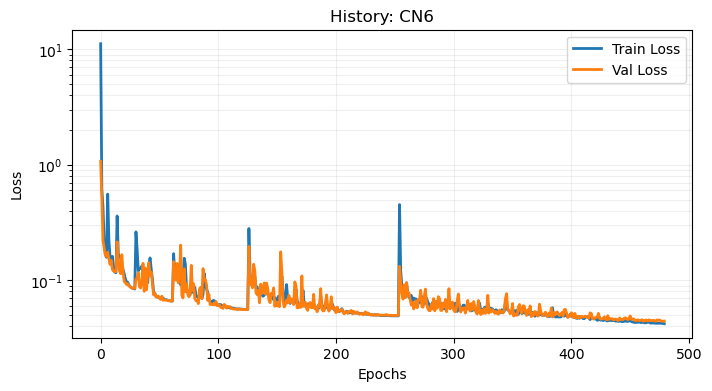

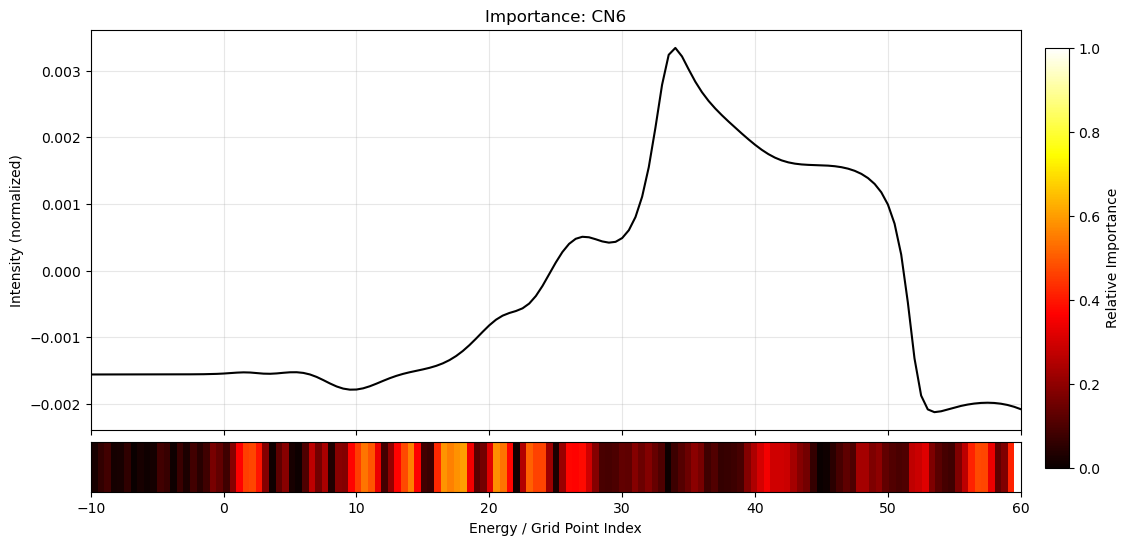

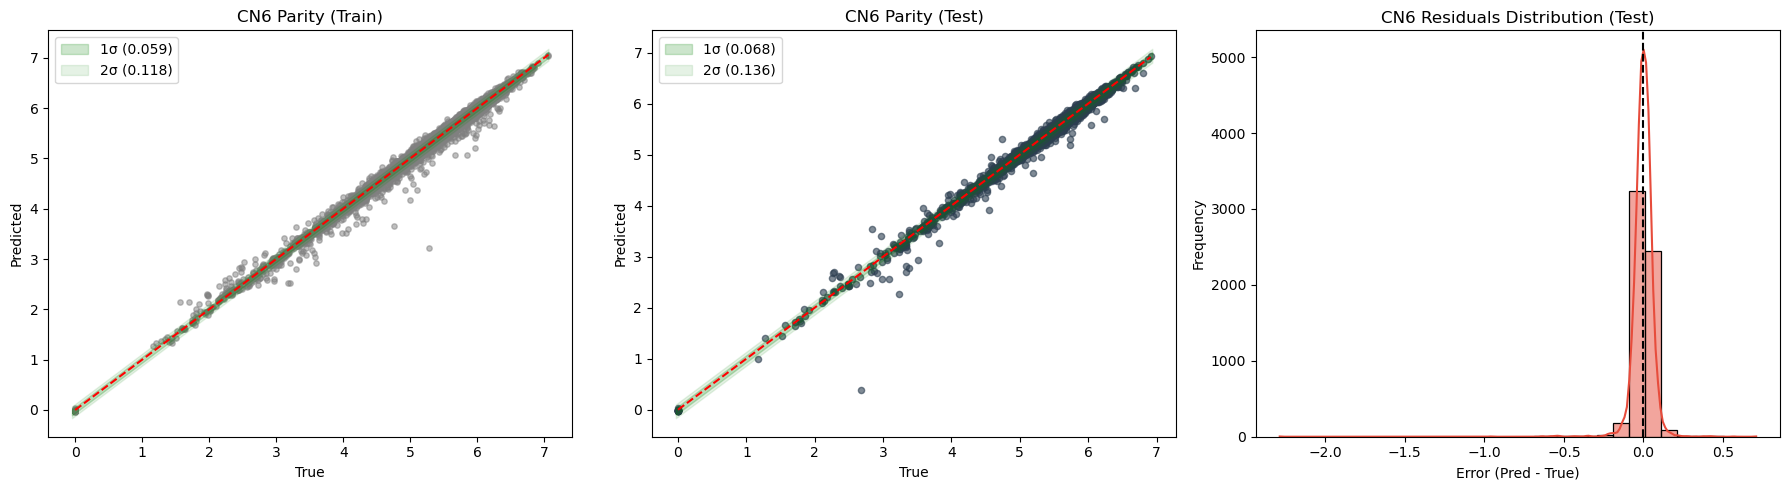


🚀 Моделирование CN7...


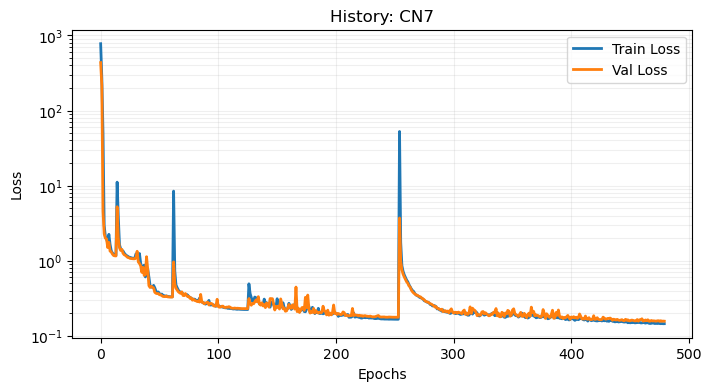

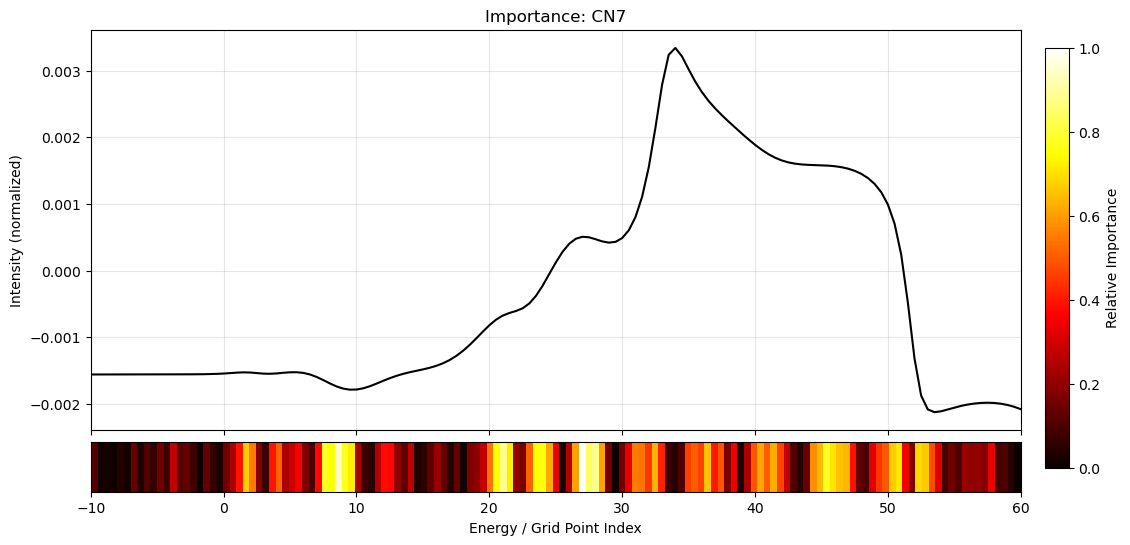

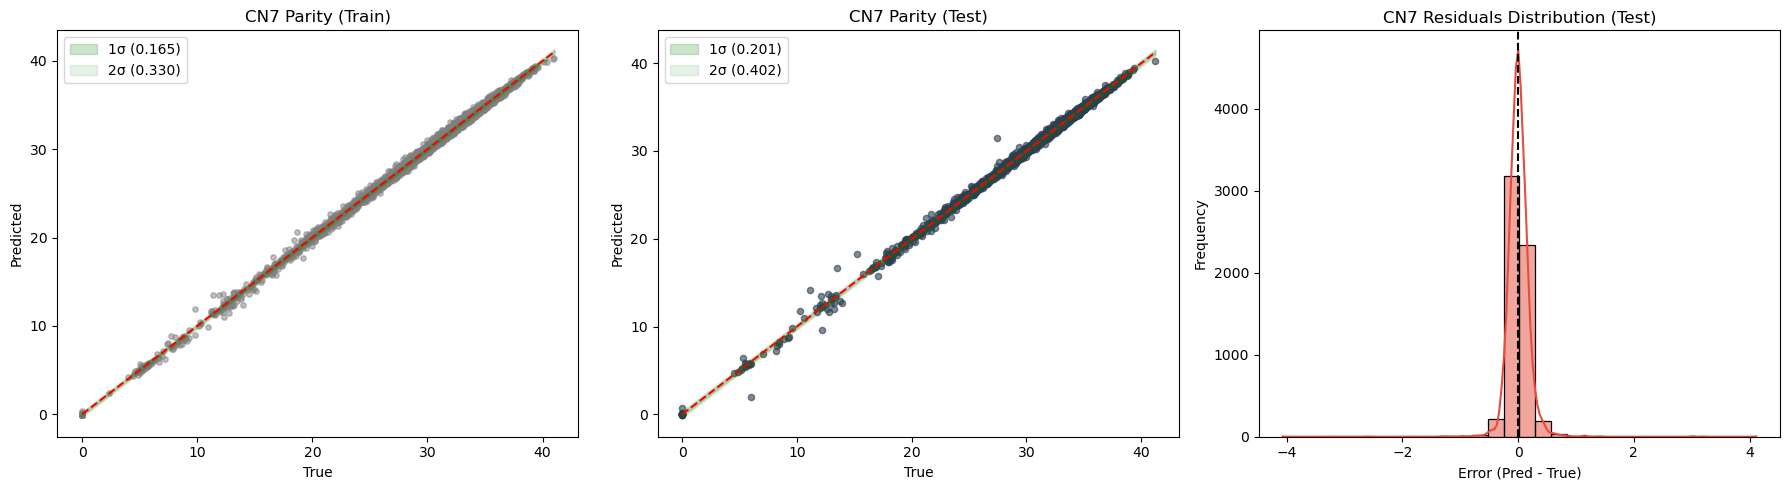


📊 ИТОГОВЫЙ ОТЧЕТ
           R2                  MAE              
Split    test  train    val   test  train    val
Target                                          
CN1    0.9997 0.9997 0.9997 0.0071 0.0071 0.0072
CN2    0.9977 0.9982 0.9979 0.0116 0.0111 0.0117
CN3    0.9990 0.9992 0.9990 0.0330 0.0316 0.0332
CN4    0.9989 0.9990 0.9988 0.0199 0.0192 0.0198
CN5    0.9976 0.9984 0.9979 0.0557 0.0521 0.0548
CN6    0.9891 0.9919 0.9905 0.0403 0.0385 0.0404
CN7    0.9973 0.9982 0.9977 0.1247 0.1177 0.1245
CPU times: total: 22min 38s
Wall time: 22min 6s


In [8]:
%%time
save_root = Path('../processed_data/Results/No_Strict_2A/MLP/')  
model = XanesNN_JanisLike(in_dim=IN_DIM)
loader = XANESDataLoader(standardize=STAND)
viz = XANESVisualizer()
nn_wrapper = TorchWrapper(model=model,params=params)
pipeline_nn = XANESPipeline(loader=loader, visualizer=viz, wrapper_instance=nn_wrapper, e_grid=E_GRID)
pipeline_nn.run(paths=paths_No_Strict, save_root=save_root)

### Сценарий 2B Lauvian


🚀 Моделирование CN1...


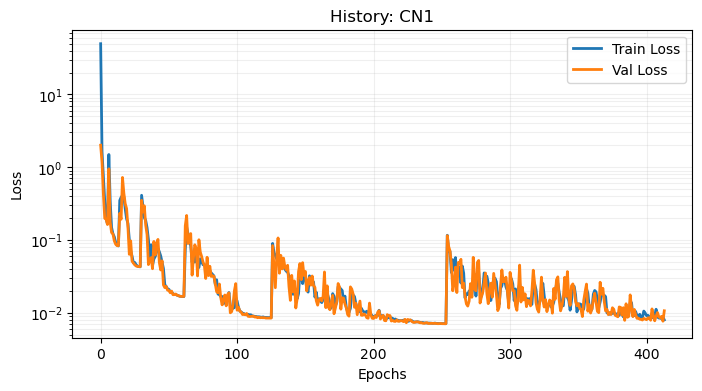

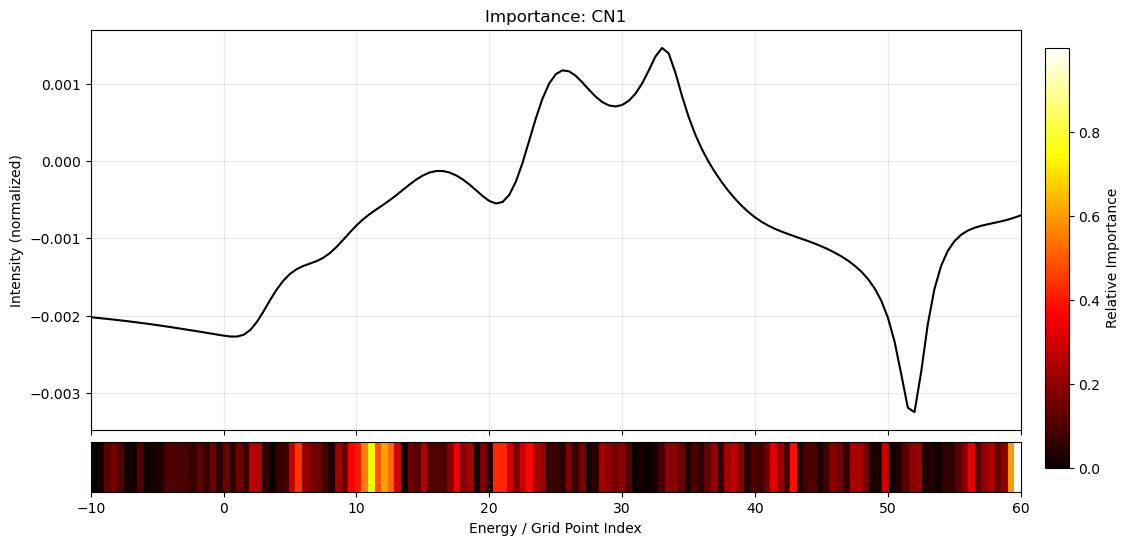

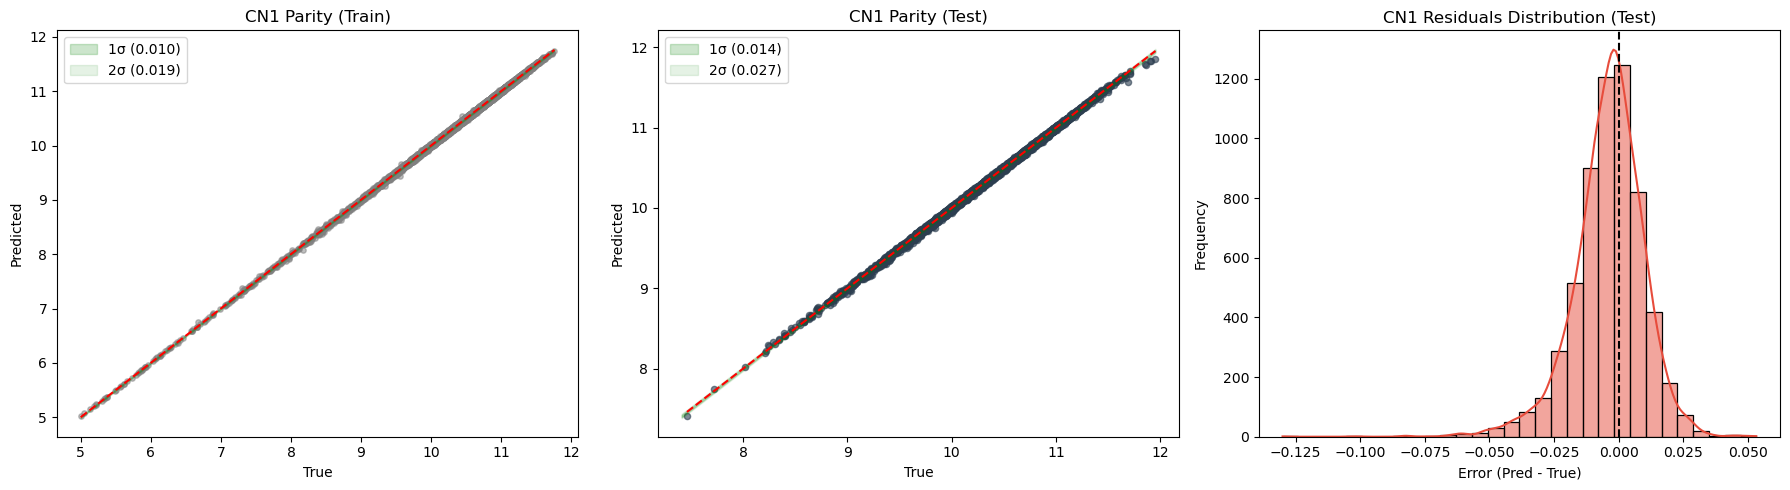


🚀 Моделирование CN2...


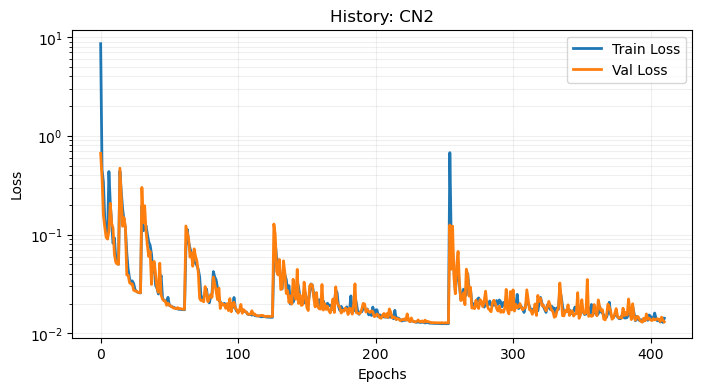

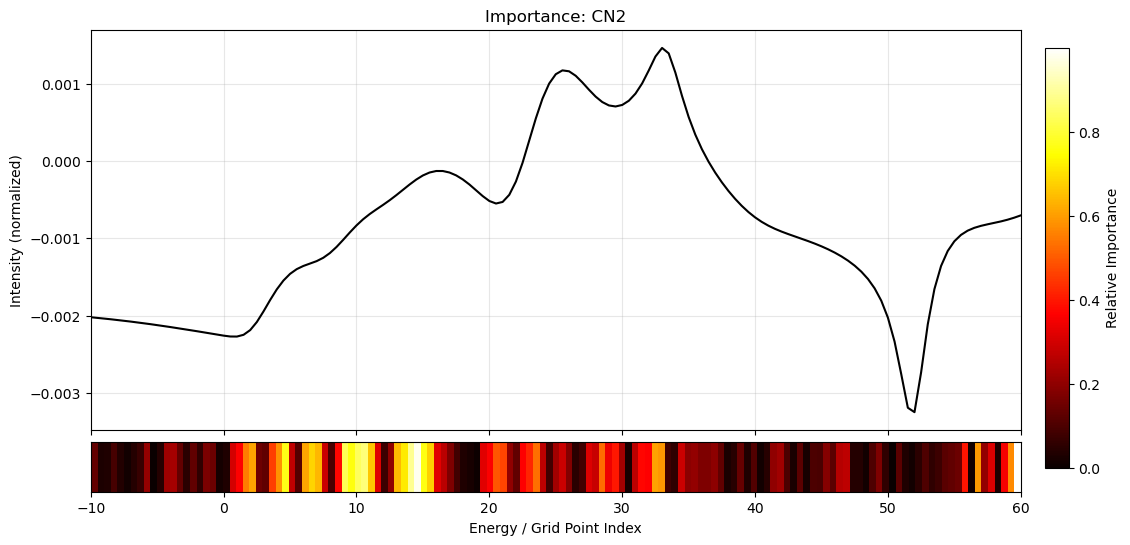

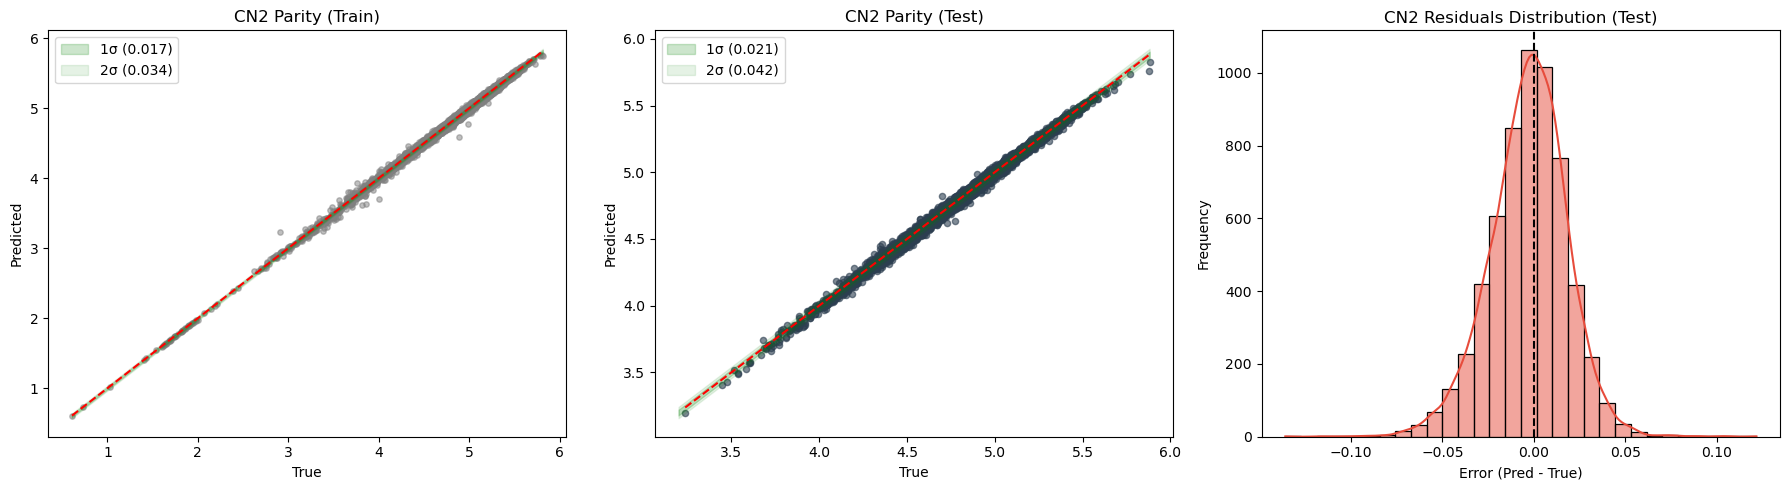


🚀 Моделирование CN3...


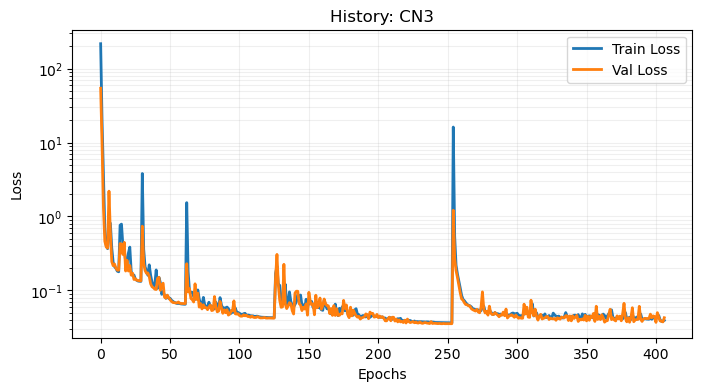

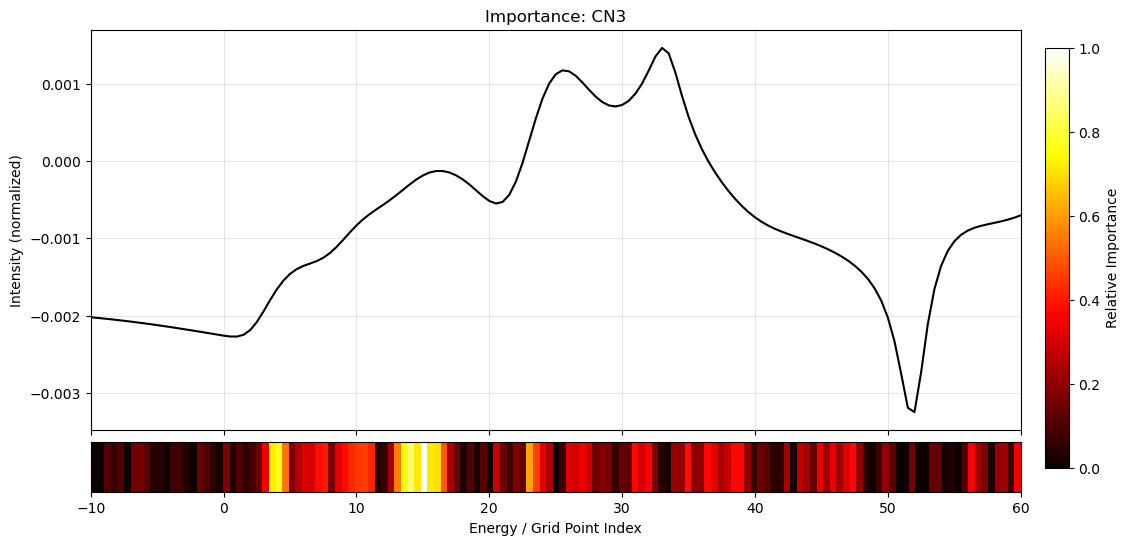

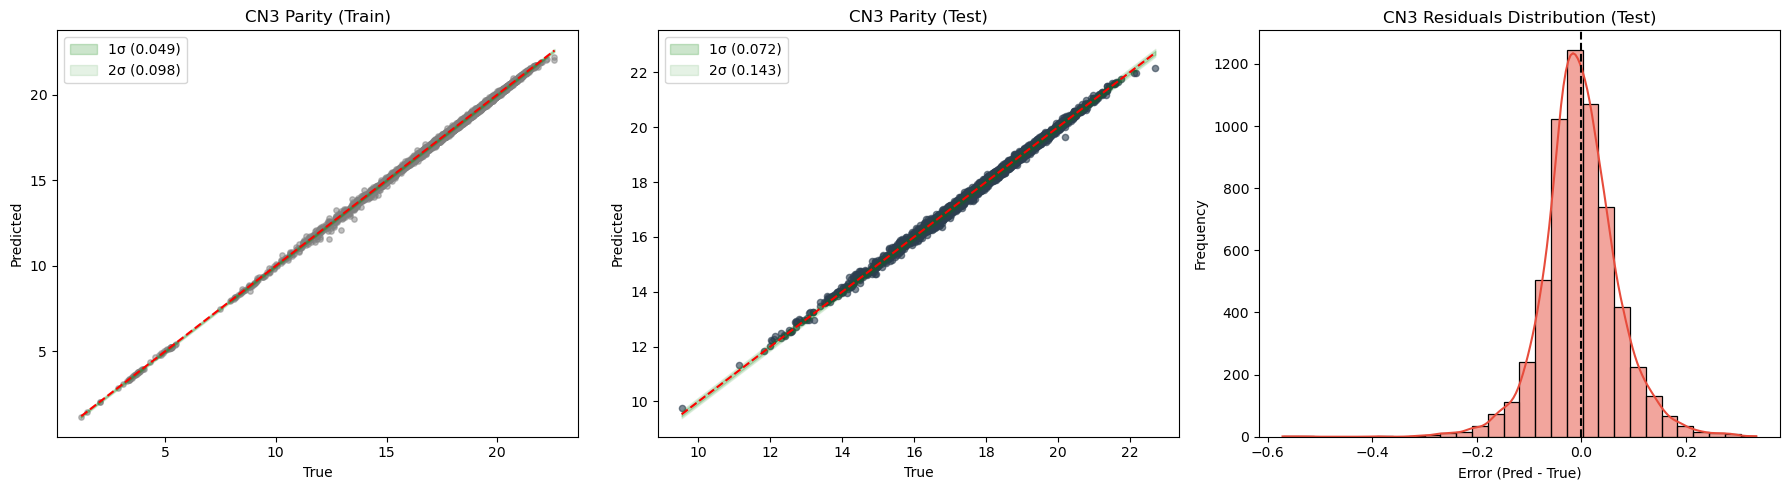


🚀 Моделирование CN4...


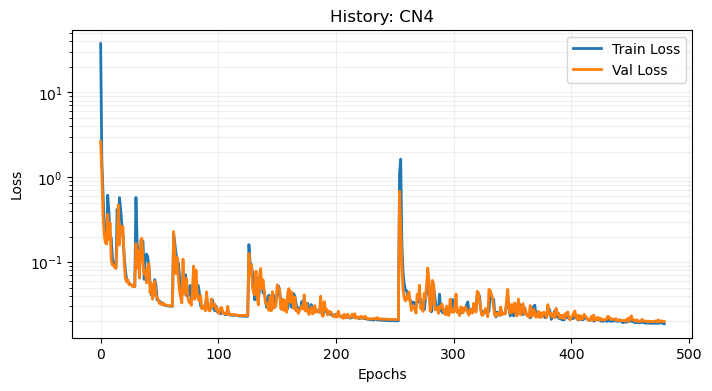

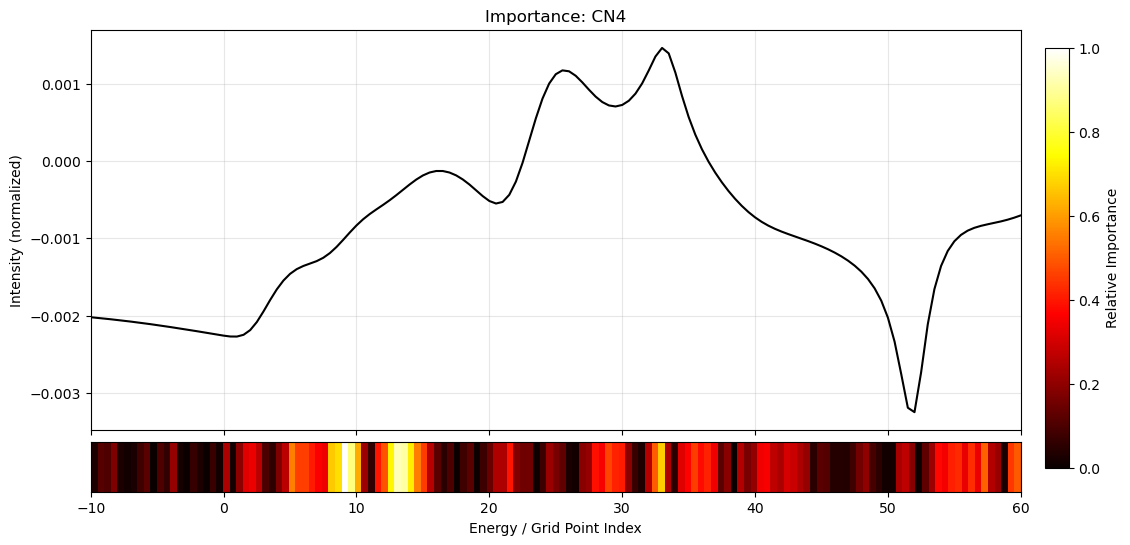

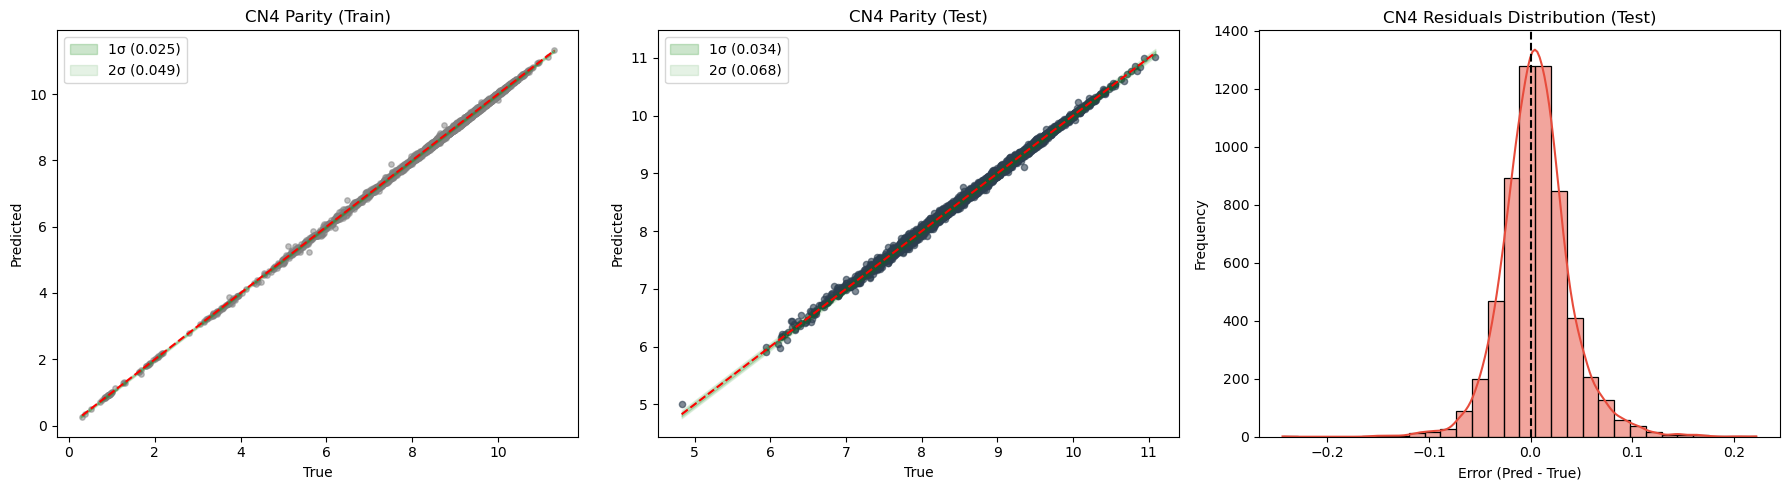


🚀 Моделирование CN5...


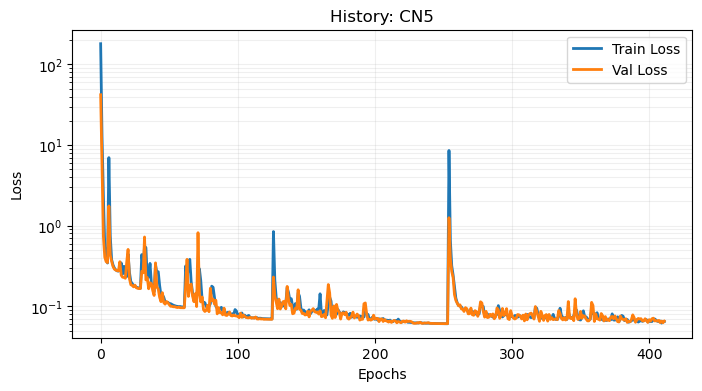

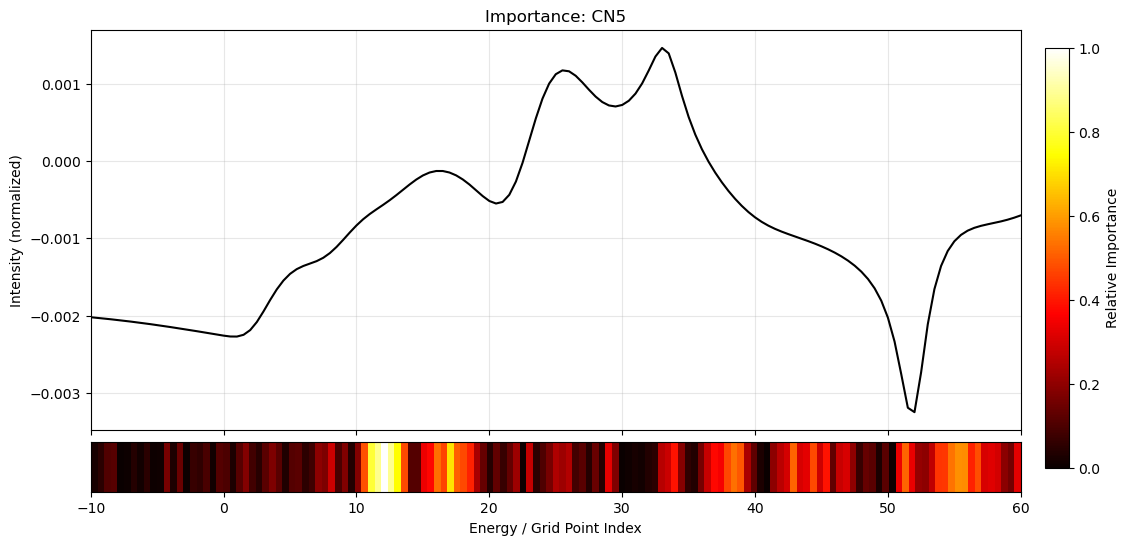

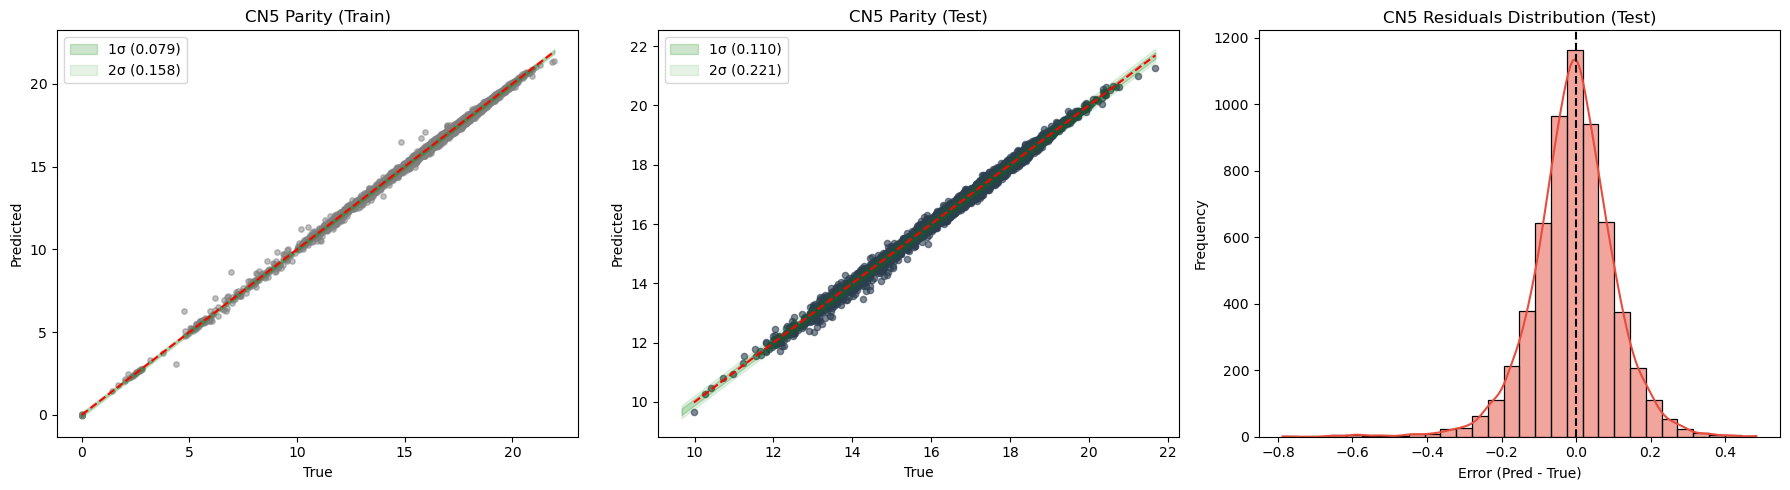


🚀 Моделирование CN6...


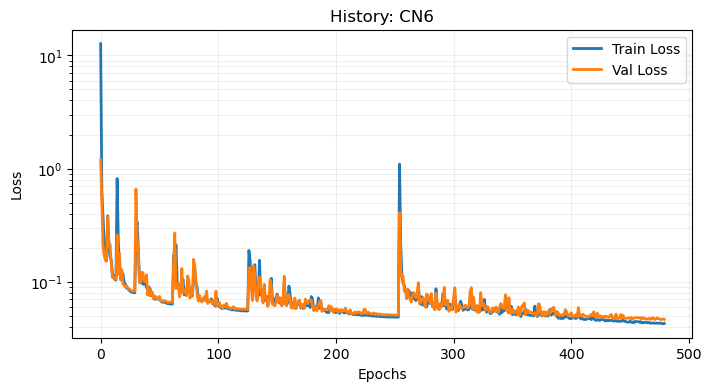

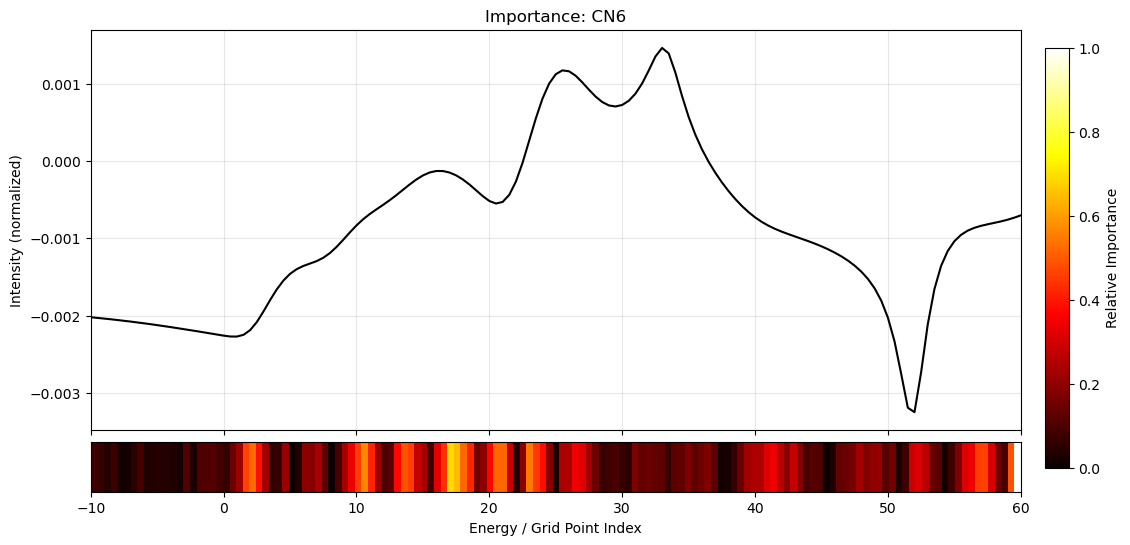

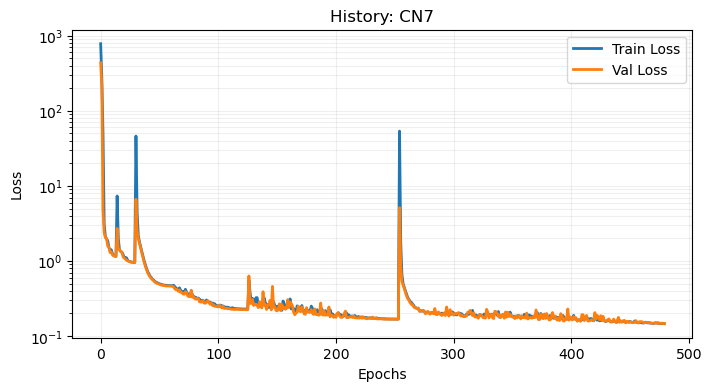

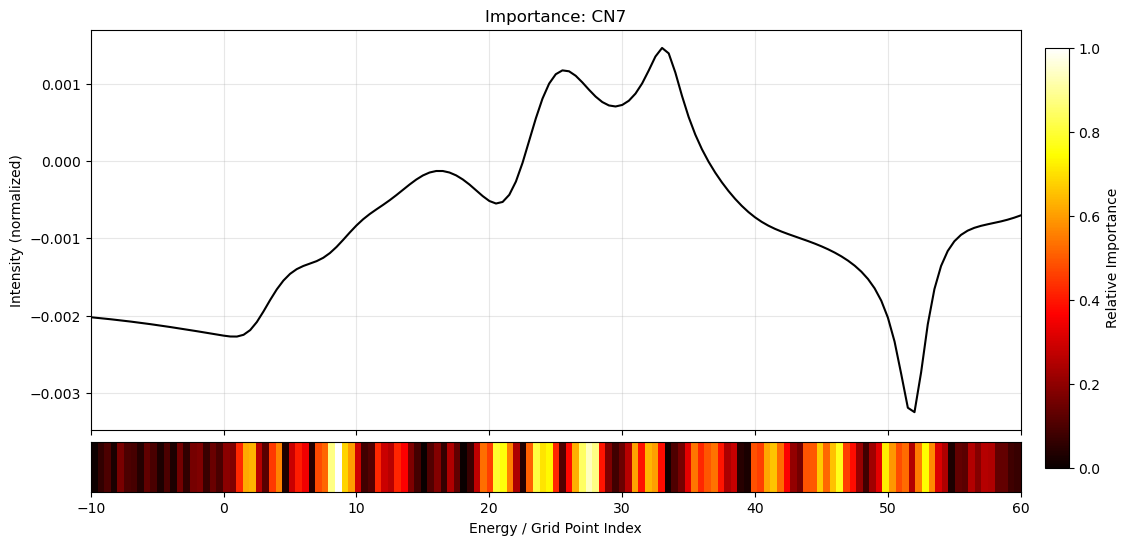

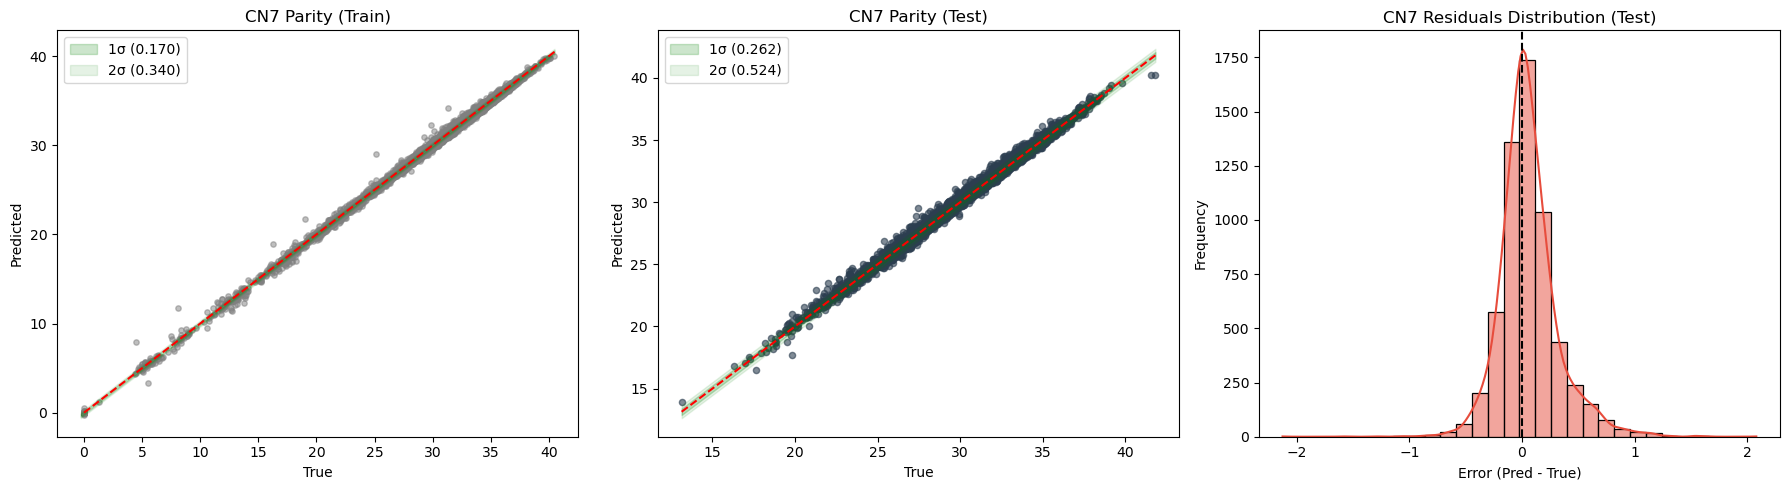


📊 ИТОГОВЫЙ ОТЧЕТ
           R2                  MAE              
Split    test  train    val   test  train    val
Target                                          
CN1    0.9992 0.9997 0.9997 0.0104 0.0070 0.0069
CN2    0.9957 0.9977 0.9978 0.0164 0.0122 0.0124
CN3    0.9974 0.9990 0.9992 0.0529 0.0340 0.0332
CN4    0.9977 0.9992 0.9991 0.0251 0.0180 0.0190
CN5    0.9948 0.9981 0.9983 0.0812 0.0545 0.0549
CN6    0.9904 0.9914 0.9845 0.0472 0.0390 0.0398
CN7    0.9938 0.9981 0.9983 0.1873 0.1161 0.1191
CPU times: total: 21min 45s
Wall time: 21min 13s


In [9]:
%%time
save_root = Path('../processed_data/Results/Lauvian_2B/MLP/')  
model = XanesNN_JanisLike(in_dim=IN_DIM)
loader = XANESDataLoader(standardize=STAND)
viz = XANESVisualizer()
nn_wrapper = TorchWrapper(model=model,params=params)
pipeline_nn = XANESPipeline(loader=loader, visualizer=viz, wrapper_instance=nn_wrapper, e_grid=E_GRID)
pipeline_nn.run(paths=paths_Lauvian, save_root=save_root)